#Capstone Project

Exploratory Data Analysis

In [ ]:
#import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from sklearn import preprocessing

In [ ]:
#reading data
df=pd.read_csv("/content/Capstone project Dataset.csv")

In [ ]:
df.head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,subscribe
0,31,blue-collar,married,basic.6y,unknown,no,no,cellular,jul,mon,...,2,999,0,nonexistent,1.4,93.918,-42.7,4.960,5228.1,no
1,32,housemaid,single,university.degree,unknown,yes,no,cellular,jul,tue,...,4,999,0,nonexistent,1.4,93.918,-42.7,4.961,5228.1,no
2,26,admin.,married,high.school,no,yes,no,cellular,apr,mon,...,1,999,0,nonexistent,-1.8,93.075,-47.1,1.405,5099.1,no
3,44,blue-collar,married,basic.4y,unknown,no,no,cellular,may,fri,...,3,999,0,nonexistent,-1.8,92.893,-46.2,1.313,5099.1,no
4,32,technician,married,unknown,no,yes,no,cellular,jul,fri,...,2,999,0,nonexistent,1.4,93.918,-42.7,4.963,5228.1,no




*  Target Variable is Subscribe.




In [ ]:
df.tail()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,subscribe
1995,27,unemployed,married,high.school,no,yes,no,cellular,may,mon,...,4,999,0,nonexistent,-1.8,92.893,-46.2,NaN,5099.1,no
1996,41,management,married,university.degree,unknown,yes,no,cellular,aug,thu,...,1,999,0,nonexistent,1.4,93.444,-36.1,NaN,5228.1,no
1997,46,self-employed,married,university.degree,no,yes,no,telephone,may,tue,...,5,999,0,nonexistent,1.1,93.994,-36.4,NaN,5191.0,no
1998,42,blue-collar,married,basic.4y,no,no,no,telephone,may,wed,...,2,999,0,nonexistent,1.1,93.994,-36.4,NaN,5191.0,no
1999,54,housemaid,married,basic.4y,unknown,no,no,cellular,jul,mon,...,20,999,0,nonexistent,1.4,93.918,-42.7,4.962,5228.1,no


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             2000 non-null   int64  
 1   job             1992 non-null   object 
 2   marital         2000 non-null   object 
 3   education       2000 non-null   object 
 4   default         2000 non-null   object 
 5   housing         2000 non-null   object 
 6   loan            2000 non-null   object 
 7   contact         2000 non-null   object 
 8   month           2000 non-null   object 
 9   day_of_week     2000 non-null   object 
 10  duration        2000 non-null   int64  
 11  campaign        2000 non-null   int64  
 12  pdays           2000 non-null   int64  
 13  previous        2000 non-null   int64  
 14  poutcome        2000 non-null   object 
 15  emp.var.rate    2000 non-null   float64
 16  cons.price.idx  2000 non-null   float64
 17  cons.conf.idx   1992 non-null   f



*  Missing value in job is 8
*  CCI is 8
*  euribor3m is 9





In [ ]:
df.shape

(2000, 21)

In [ ]:
df.describe()

,age,duration,campaign,pdays,previous,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed
count,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,1992.000000,1991.000000,2000.000000
mean,40.245500,250.380000,3.005000,964.745000,0.171000,0.101350,93.579410,-40.591516,3.639012,5167.775650
std,10.484188,245.386067,10.187633,181.260237,0.492829,1.551405,0.564451,4.564793,1.725053,71.453919
min,18.000000,4.000000,0.000000,1.000000,0.000000,-3.400000,92.201000,-50.800000,0.634000,4963.600000
25%,32.000000,103.000000,1.000000,999.000000,0.000000,-1.800000,93.075000,-42.700000,1.354000,5099.100000
50%,38.000000,173.000000,2.000000,999.000000,0.000000,1.100000,93.749000,-41.800000,4.857000,5191.000000
75%,48.000000,306.250000,3.000000,999.000000,0.000000,1.400000,93.994000,-36.400000,4.961000,5228.100000
max,85.000000,2635.000000,300.000000,999.000000,5.000000,1.400000,94.767000,-26.900000,5.000000,5228.100000


In [ ]:
df.columns = df.columns.str.strip()
display(df.columns)

Index(['age', 'job', 'marital', 'education', 'default', 'housing', 'loan',
       'contact', 'month', 'day_of_week', 'duration', 'campaign', 'pdays',
       'previous', 'poutcome', 'emp.var.rate', 'cons.price.idx',
       'cons.conf.idx', 'euribor3m', 'nr.employed', 'subscribe'],
      dtype='object')

#Missing Value Treatment

In [ ]:
print('Missing values per column:')
display(df.isnull().sum())

Missing values per column:


,0
age,0
job,8
marital,0
education,0
default,0
housing,0
loan,0
contact,0
month,0
day_of_week,0


In [ ]:
# Impute 'job' column with 'unknown' as unknown is a category given in the job column
df.fillna({'job':"unknown"}, inplace=True)


display(df.isnull().sum())

,0
age,0
job,0
marital,0
education,0
default,0
housing,0
loan,0
contact,0
month,0
day_of_week,0


In [ ]:
# Replace specific string values 'NA' and 'job' with 'unknown' in the 'job' column


df['job'] = df['job'].str.strip()
df['job'] = df['job'].replace(['NA', 'job'], 'unknown')

print("Unique values in 'job' column right now:")
print(df['job'].unique())

Unique values in 'job' column right now:
['blue-collar' 'housemaid' 'admin.' 'technician' 'services' 'management'
 'unknown' 'retired' 'student' 'self-employed' 'entrepreneur' 'unemployed']


In [ ]:
#cons.conf.idx	col has mean and median closer and values ranging from minimum of -50.8 and  maximum of -26.9. So, imputing it with median.

# Impute 'cons.conf.idx' column with its median
df.fillna({'cons.conf.idx':df['cons.conf.idx'].median()}, inplace=True)
# Impute 'euribor3m' column with its median
df.fillna({'euribor3m':df['euribor3m'].median()}, inplace=True)

# Display missing values after imputation to confirm
print('Missing values after imputing cons.conf.idx and euribor3m:')
display(df.isnull().sum())

Missing values after imputing cons.conf.idx and euribor3m:


,0
age,0
job,0
marital,0
education,0
default,0
housing,0
loan,0
contact,0
month,0
day_of_week,0


### Data Exploration: Numeric Features Distribution and Skewness

We will now examine the distribution of each numerical feature using histograms and box plots, and calculate their skewness. This will help us understand their shape, spread, and identify potential outliers or transformations needed.


--- Analyzing column: age ---
Skewness: 0.66


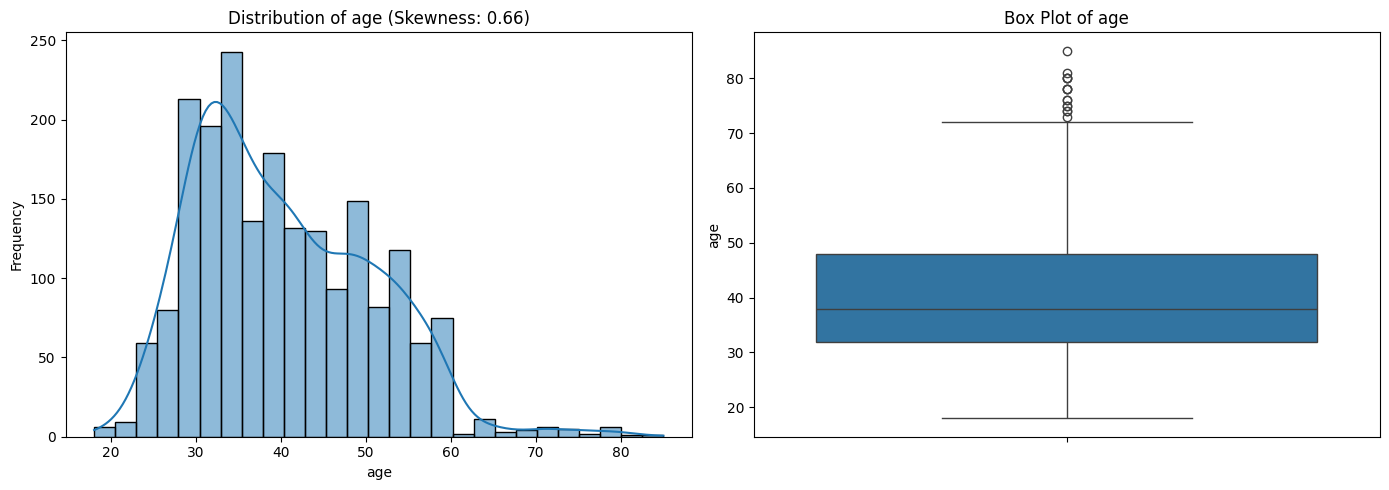


--- Analyzing column: duration ---
Skewness: 2.95


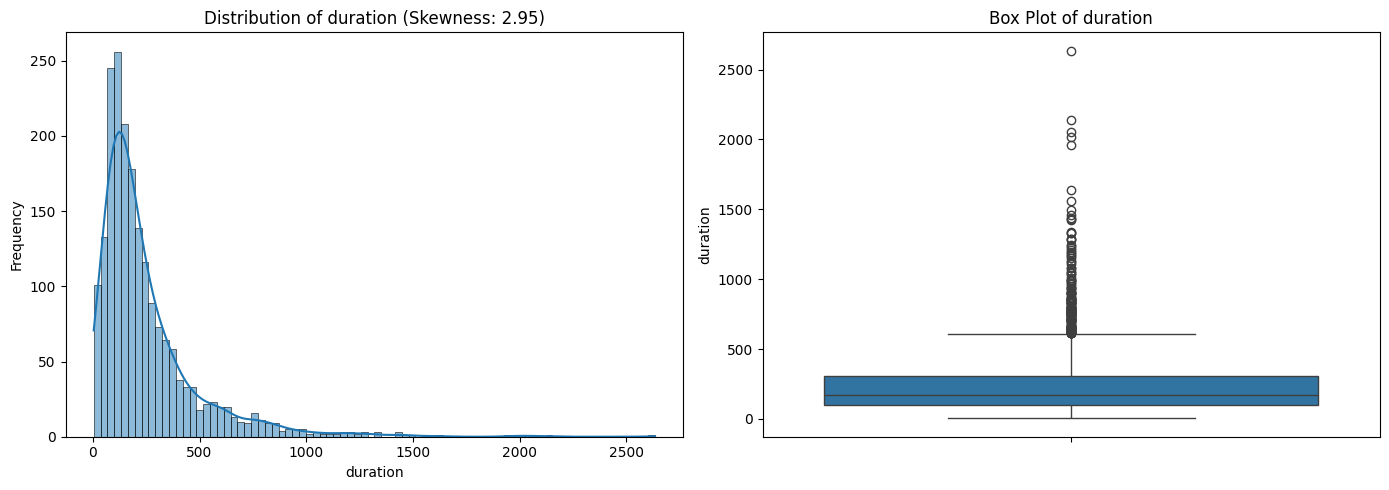


--- Analyzing column: campaign ---
Skewness: 25.41


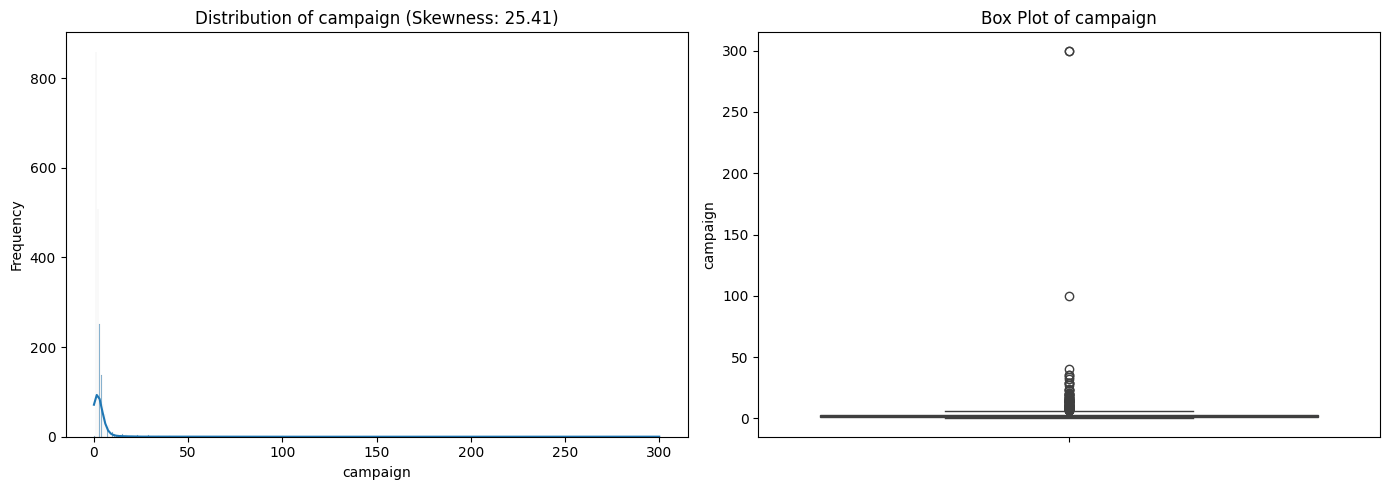


--- Analyzing column: pdays ---
Skewness: -5.11


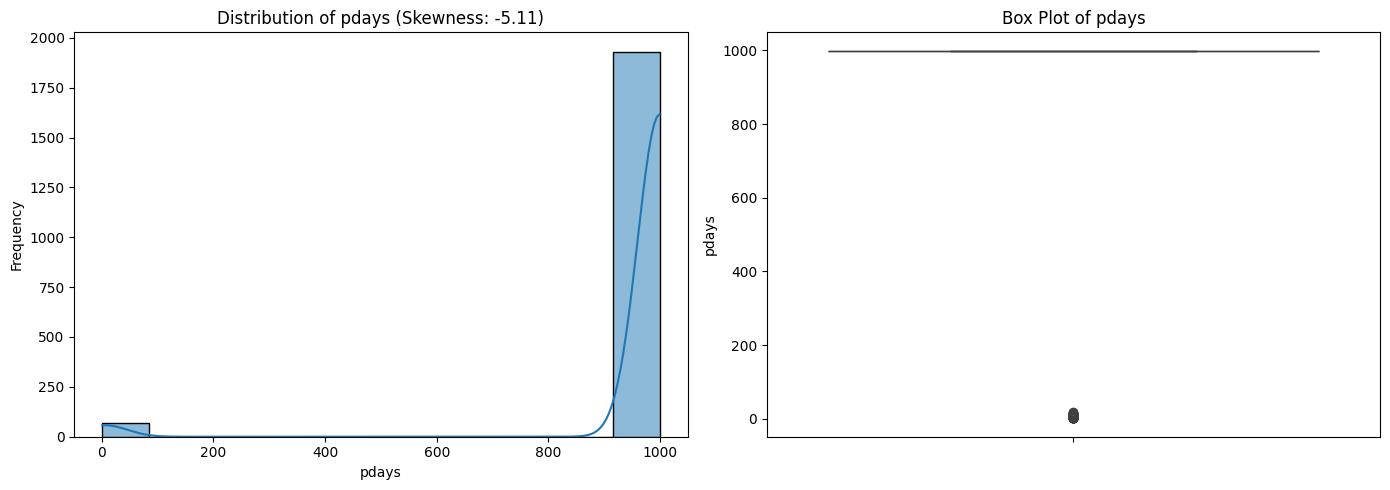


--- Analyzing column: previous ---
Skewness: 3.89


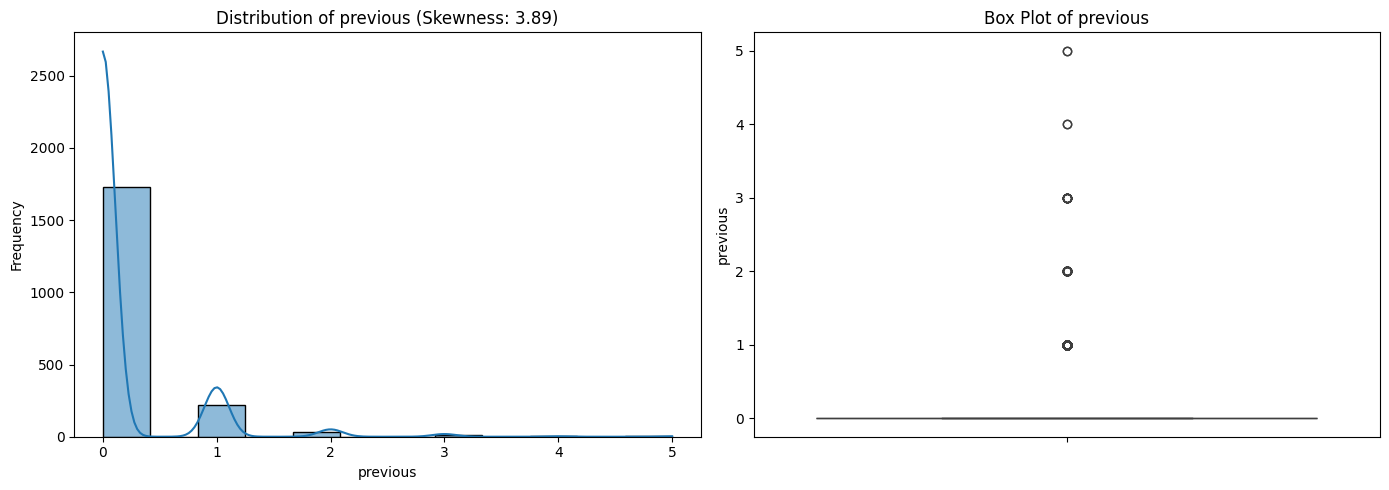


--- Analyzing column: emp.var.rate ---
Skewness: -0.73


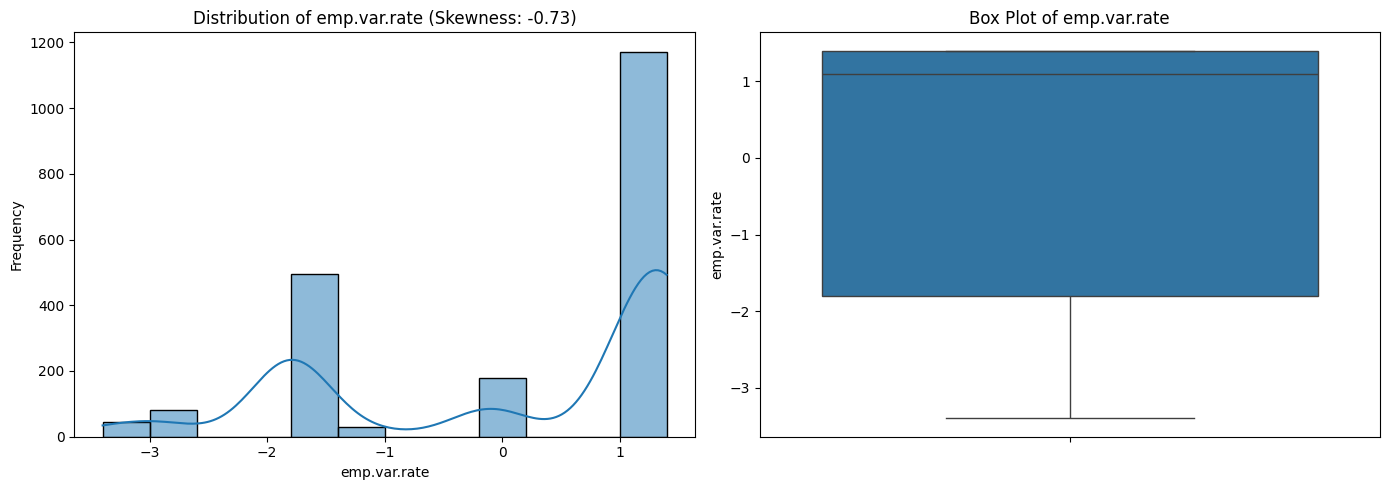


--- Analyzing column: cons.price.idx ---
Skewness: -0.21


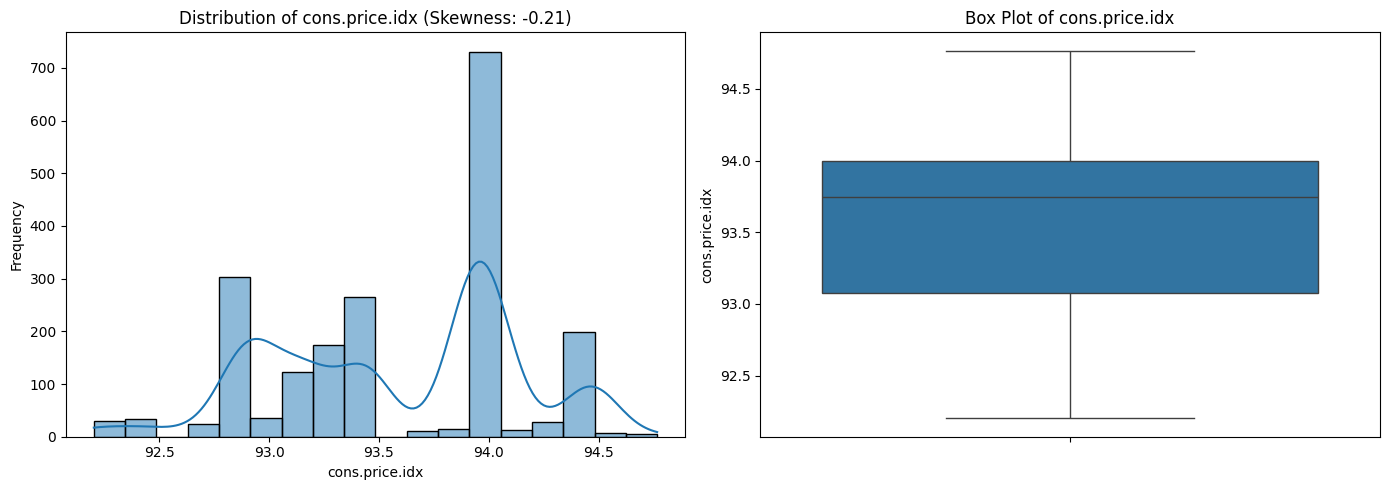


--- Analyzing column: cons.conf.idx ---
Skewness: 0.27


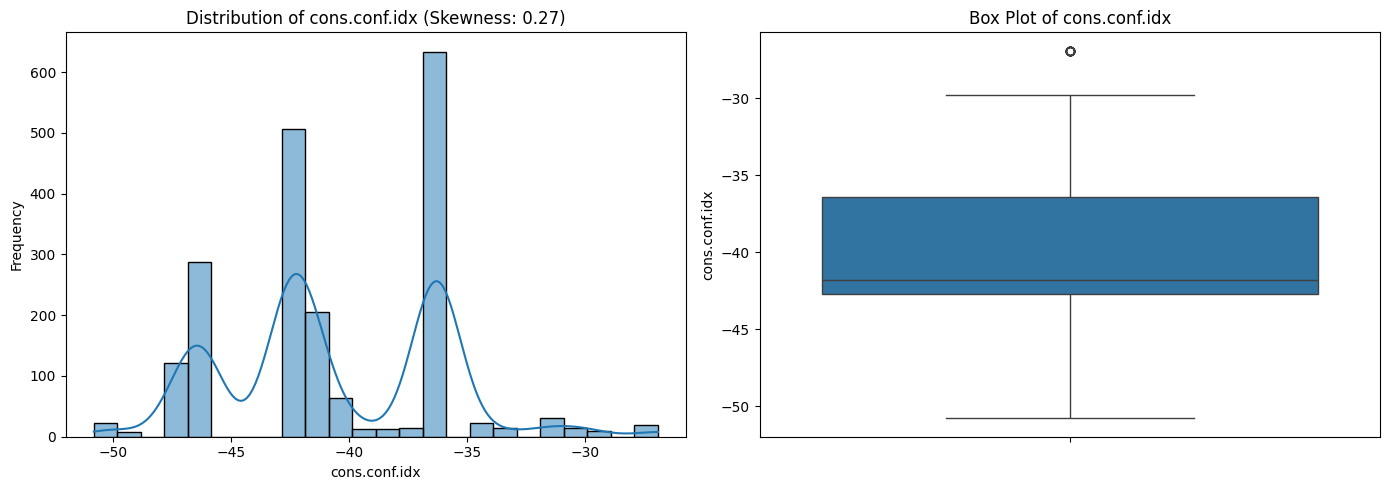


--- Analyzing column: euribor3m ---
Skewness: -0.73


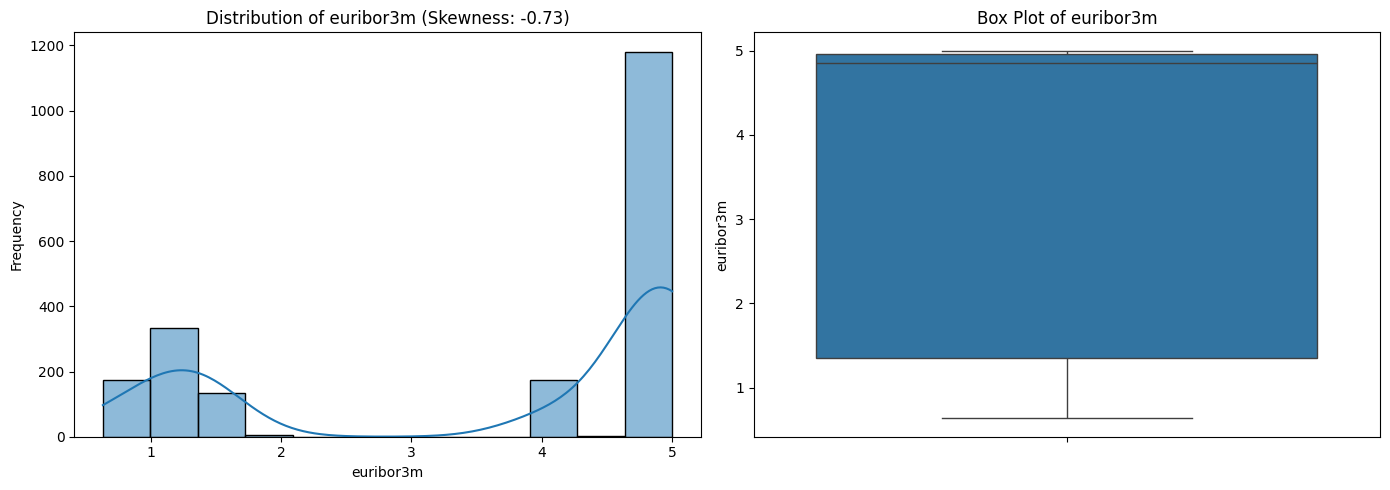


--- Analyzing column: nr.employed ---
Skewness: -1.06


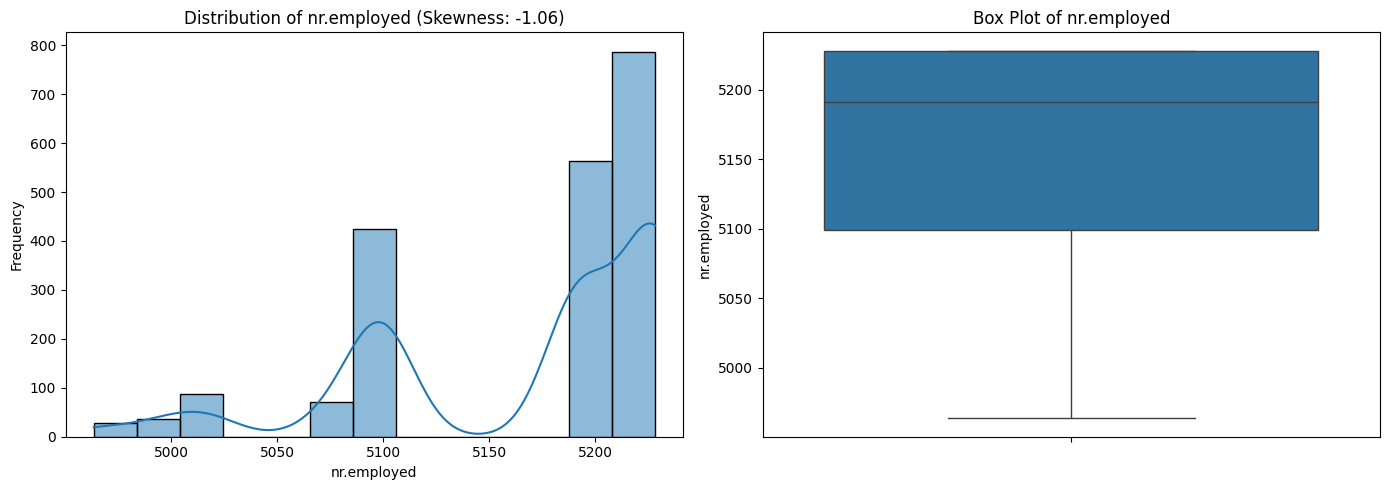

In [ ]:
numeric_cols = df.select_dtypes(include=np.number).columns

for col in numeric_cols:
    print(f"\n--- Analyzing column: {col} ---")
    print(f"Skewness: {df[col].skew():.2f}")

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # Histogram
    sns.histplot(df[col], kde=True, ax=axes[0])
    axes[0].set_title(f'Distribution of {col} (Skewness: {df[col].skew():.2f})')
    axes[0].set_xlabel(col)
    axes[0].set_ylabel('Frequency')

    # Box plot
    sns.boxplot(y=df[col], ax=axes[1])
    axes[1].set_title(f'Box Plot of {col}')
    axes[1].set_ylabel(col)

    plt.tight_layout()
    plt.show()

Dropping Duration

In [ ]:
#drop duration, bcz they havent been contacted yet so the y will be 0 .
df = df.drop('duration', axis=1)

print("DataFrame after dropping 'duration' column:")
display(df.head())
print('\nDataFrame Info after dropping \'duration\' column:')
df.info()

DataFrame after dropping 'duration' column:


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,subscribe
0,31,blue-collar,married,basic.6y,unknown,no,no,cellular,jul,mon,2,999,0,nonexistent,1.4,93.918,-42.7,4.960,5228.1,no
1,32,housemaid,single,university.degree,unknown,yes,no,cellular,jul,tue,4,999,0,nonexistent,1.4,93.918,-42.7,4.961,5228.1,no
2,26,admin.,married,high.school,no,yes,no,cellular,apr,mon,1,999,0,nonexistent,-1.8,93.075,-47.1,1.405,5099.1,no
3,44,blue-collar,married,basic.4y,unknown,no,no,cellular,may,fri,3,999,0,nonexistent,-1.8,92.893,-46.2,1.313,5099.1,no
4,32,technician,married,unknown,no,yes,no,cellular,jul,fri,2,999,0,nonexistent,1.4,93.918,-42.7,4.963,5228.1,no



DataFrame Info after dropping 'duration' column:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 20 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             2000 non-null   int64  
 1   job             2000 non-null   object 
 2   marital         2000 non-null   object 
 3   education       2000 non-null   object 
 4   default         2000 non-null   object 
 5   housing         2000 non-null   object 
 6   loan            2000 non-null   object 
 7   contact         2000 non-null   object 
 8   month           2000 non-null   object 
 9   day_of_week     2000 non-null   object 
 10  campaign        2000 non-null   int64  
 11  pdays           2000 non-null   int64  
 12  previous        2000 non-null   int64  
 13  poutcome        2000 non-null   object 
 14  emp.var.rate    2000 non-null   float64
 15  cons.price.idx  2000 non-null   float64
 16  cons.conf.idx   2000 non-nul

count plot for categorial data

/tmp/ipykernel_841/1831641214.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x=col, palette='viridis')


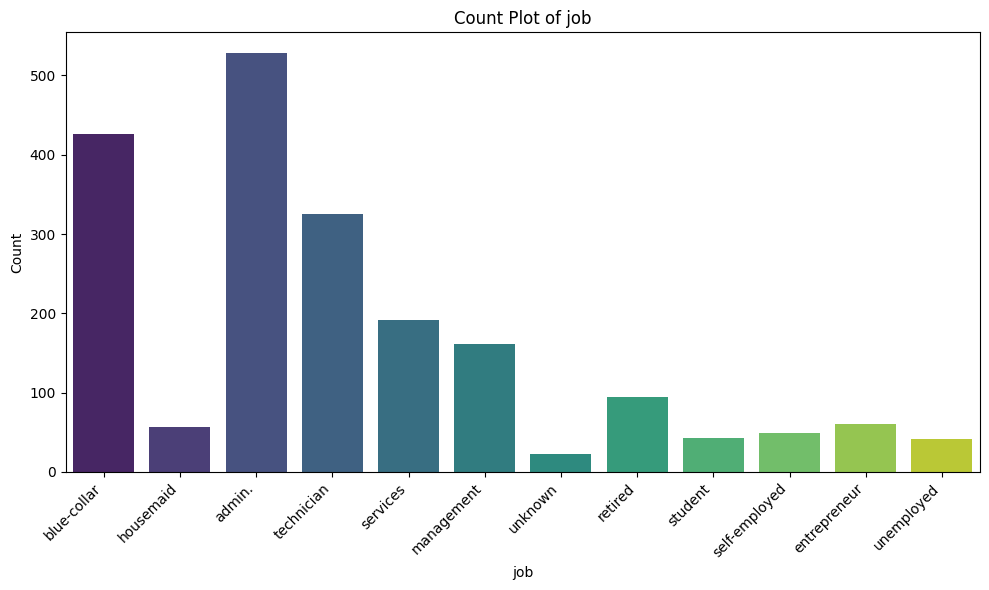

/tmp/ipykernel_841/1831641214.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x=col, palette='viridis')


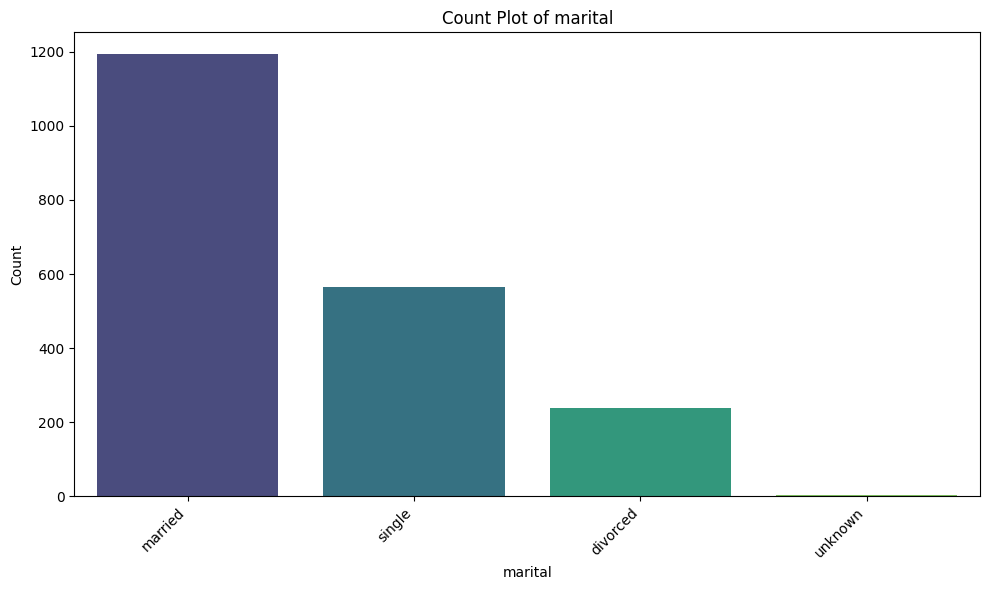

/tmp/ipykernel_841/1831641214.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x=col, palette='viridis')


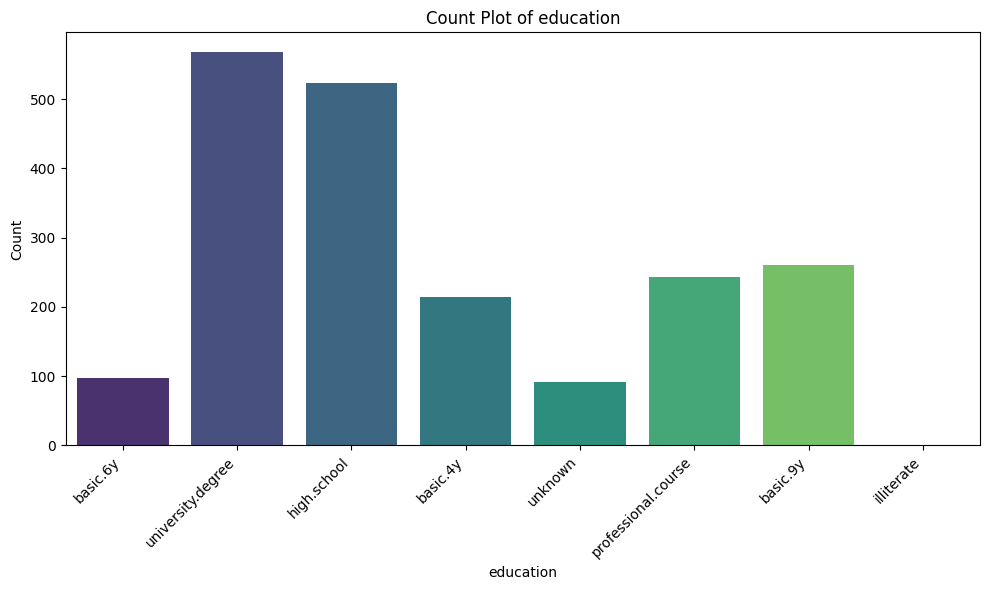

/tmp/ipykernel_841/1831641214.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x=col, palette='viridis')


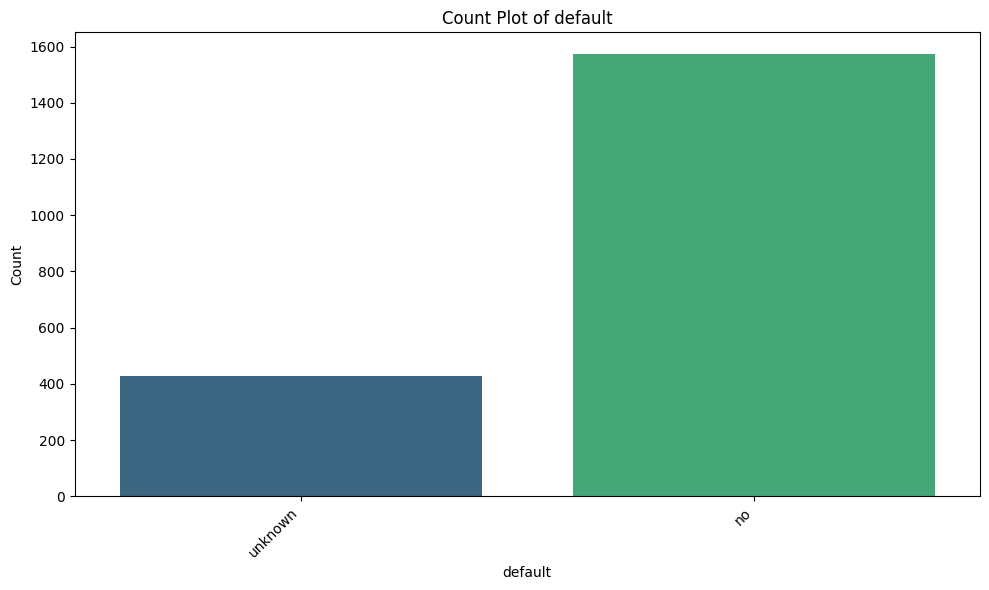

/tmp/ipykernel_841/1831641214.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x=col, palette='viridis')


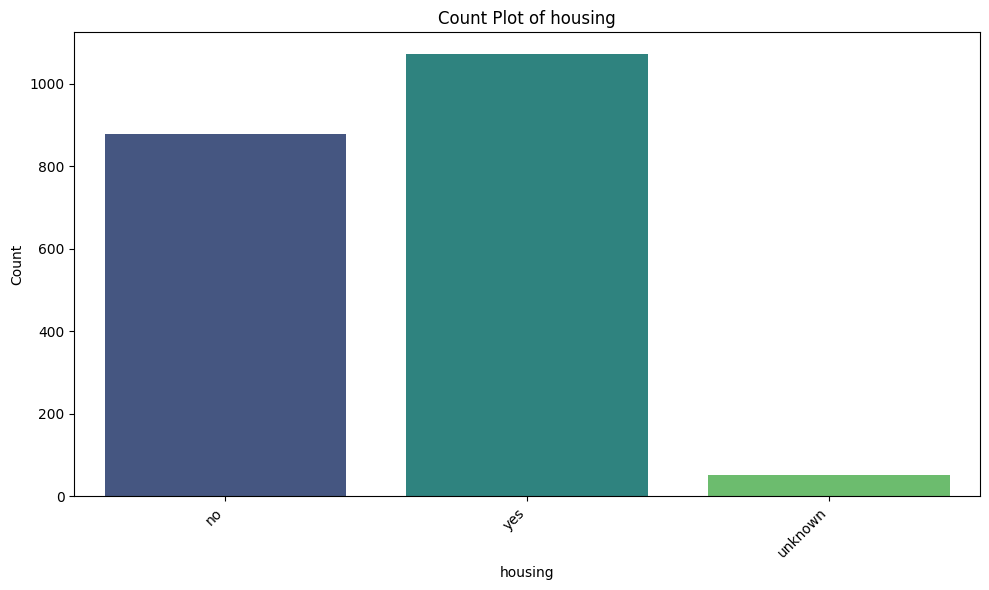

/tmp/ipykernel_841/1831641214.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x=col, palette='viridis')


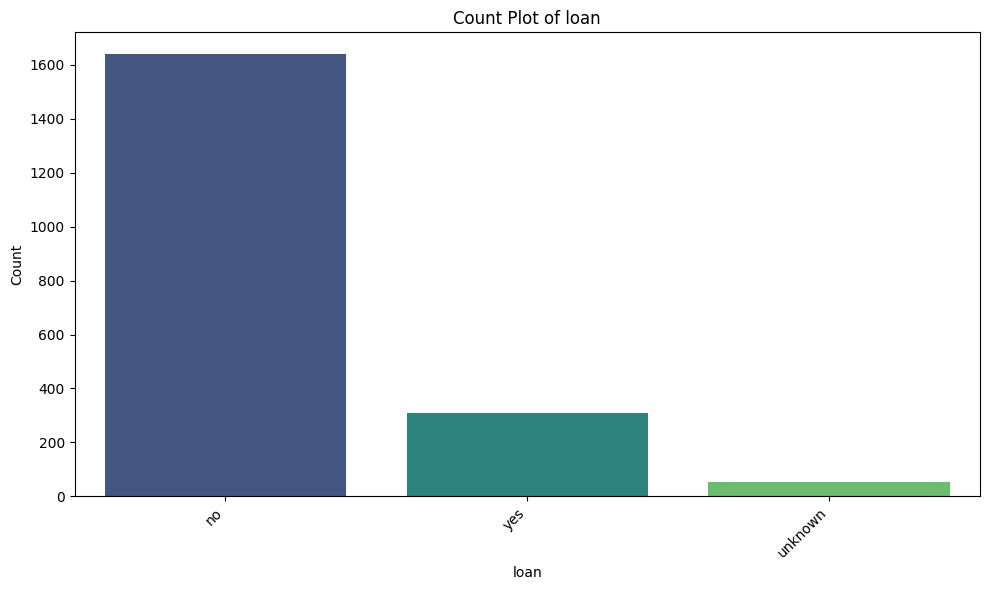

/tmp/ipykernel_841/1831641214.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x=col, palette='viridis')


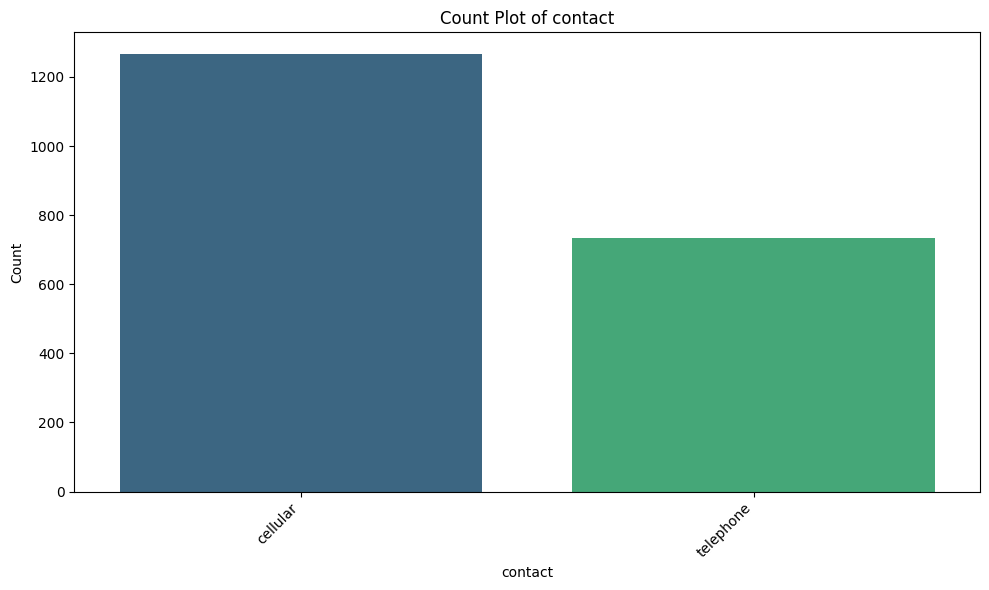

/tmp/ipykernel_841/1831641214.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x=col, palette='viridis')


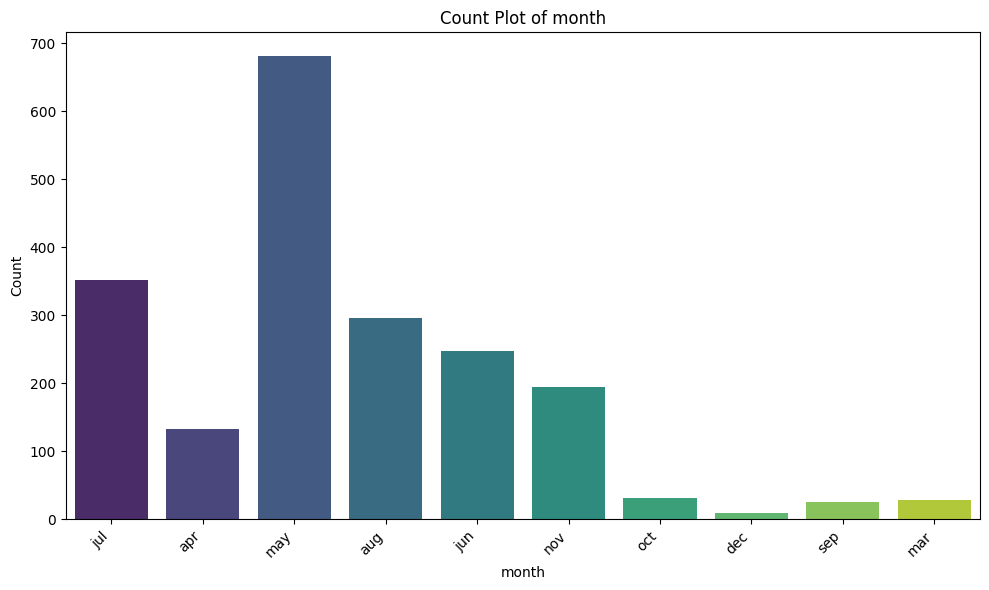

/tmp/ipykernel_841/1831641214.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x=col, palette='viridis')


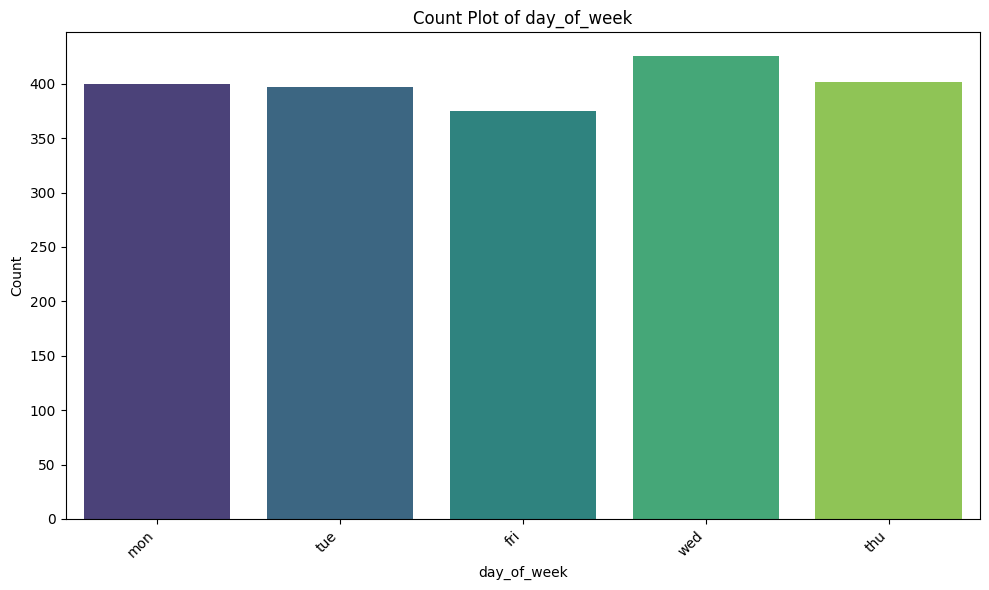

/tmp/ipykernel_841/1831641214.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x=col, palette='viridis')


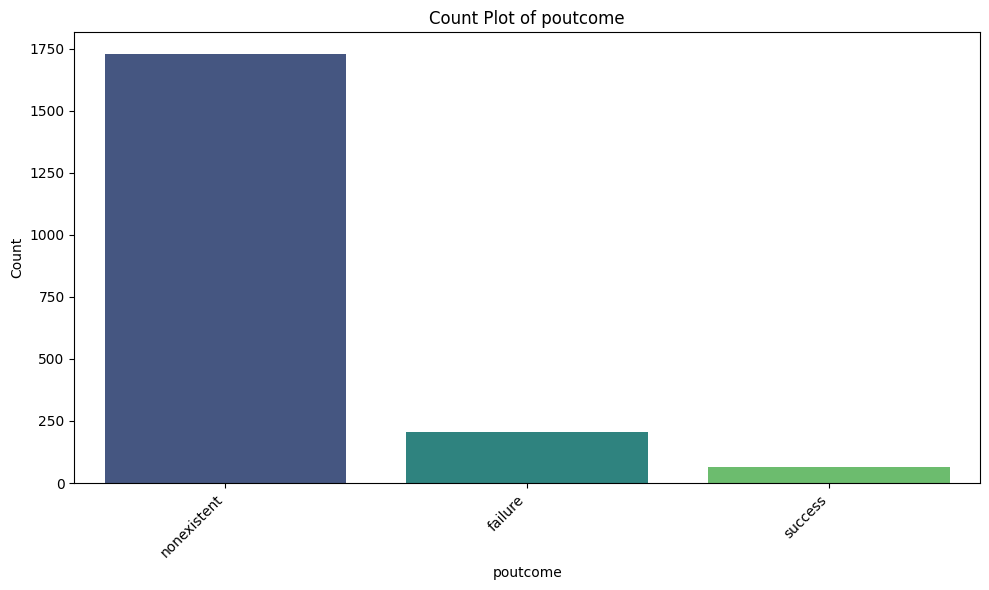

/tmp/ipykernel_841/1831641214.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x=col, palette='viridis')


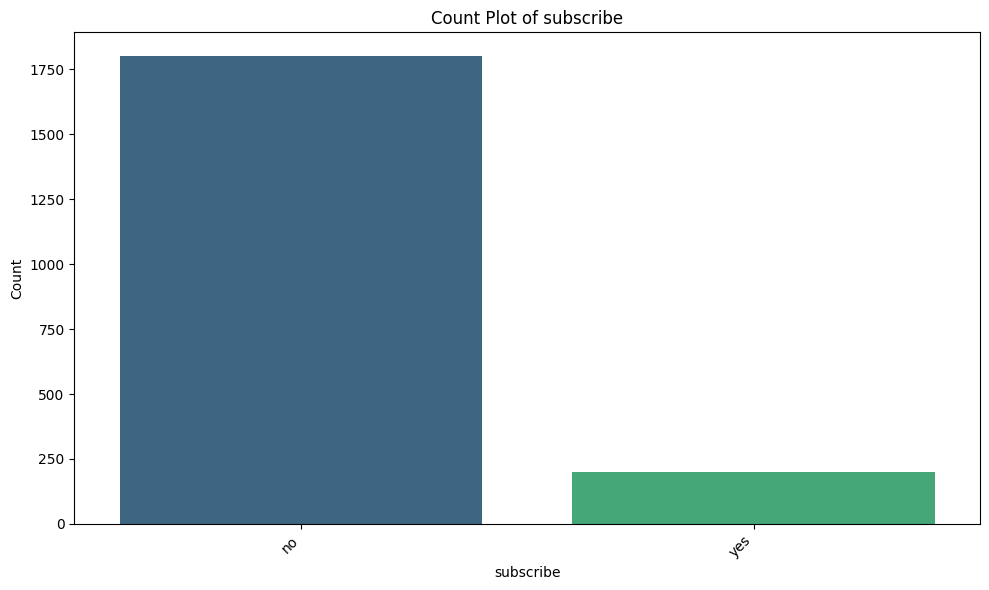

In [ ]:

# Original code for generating count plots for categorical data
categorical_cols = df.select_dtypes(include='object').columns

for col in categorical_cols:
    plt.figure(figsize=(10, 6))
    sns.countplot(data=df, x=col, palette='viridis')
    plt.title(f'Count Plot of {col}')
    plt.xlabel(col)
    plt.ylabel('Count')
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()

### Two-way Box Plots: Numeric Features vs. Categorical Target ('subscribe')

/tmp/ipykernel_841/1724083384.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='subscribe', y=col, data=df, palette='pastel')


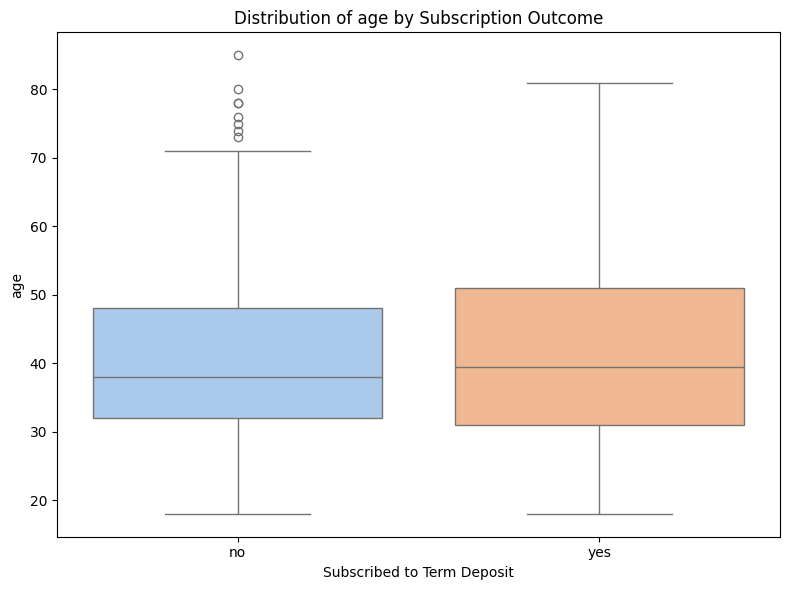

/tmp/ipykernel_841/1724083384.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='subscribe', y=col, data=df, palette='pastel')


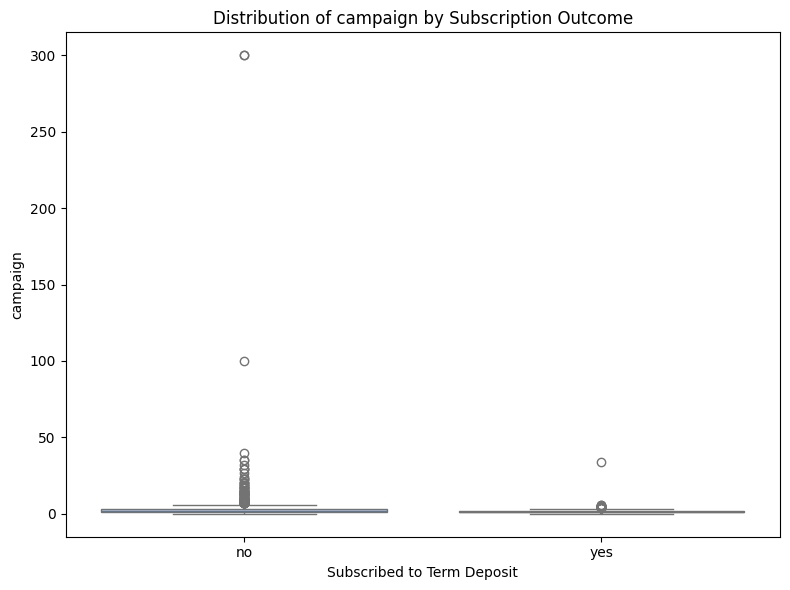

/tmp/ipykernel_841/1724083384.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='subscribe', y=col, data=df, palette='pastel')


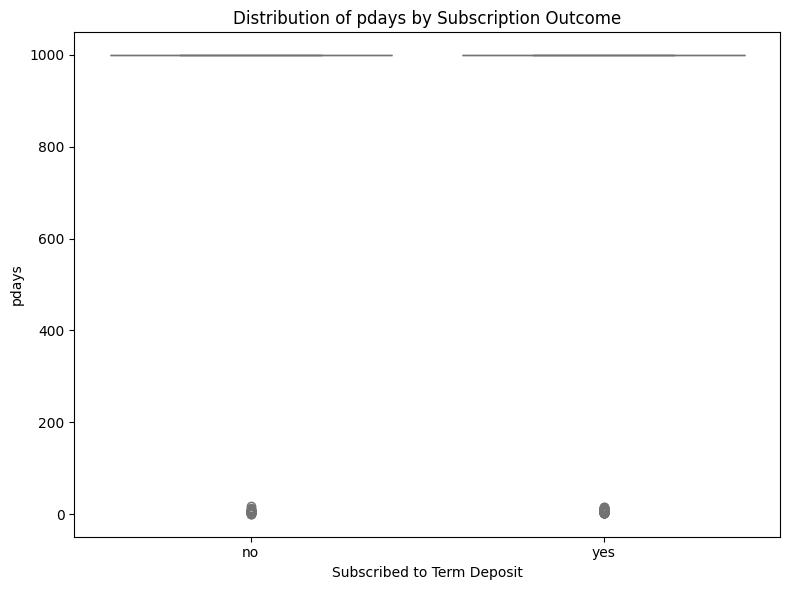

/tmp/ipykernel_841/1724083384.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='subscribe', y=col, data=df, palette='pastel')


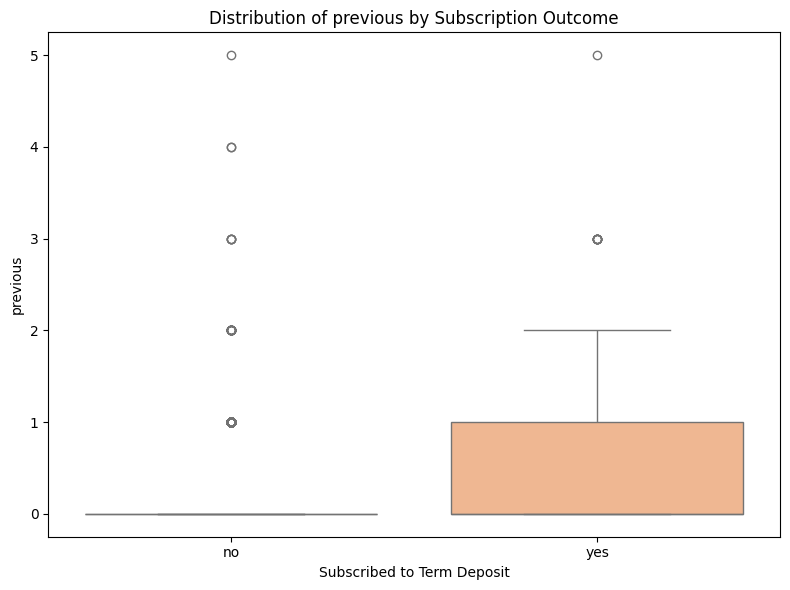

/tmp/ipykernel_841/1724083384.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='subscribe', y=col, data=df, palette='pastel')


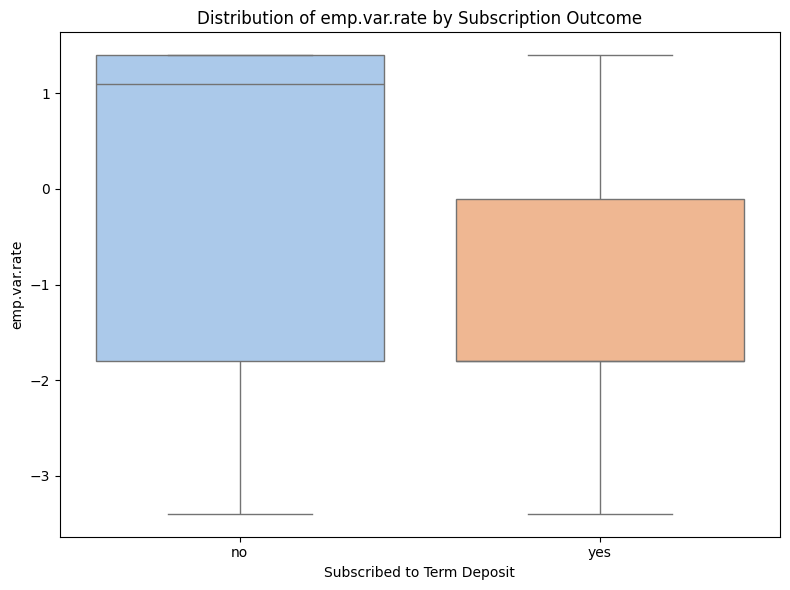

/tmp/ipykernel_841/1724083384.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='subscribe', y=col, data=df, palette='pastel')


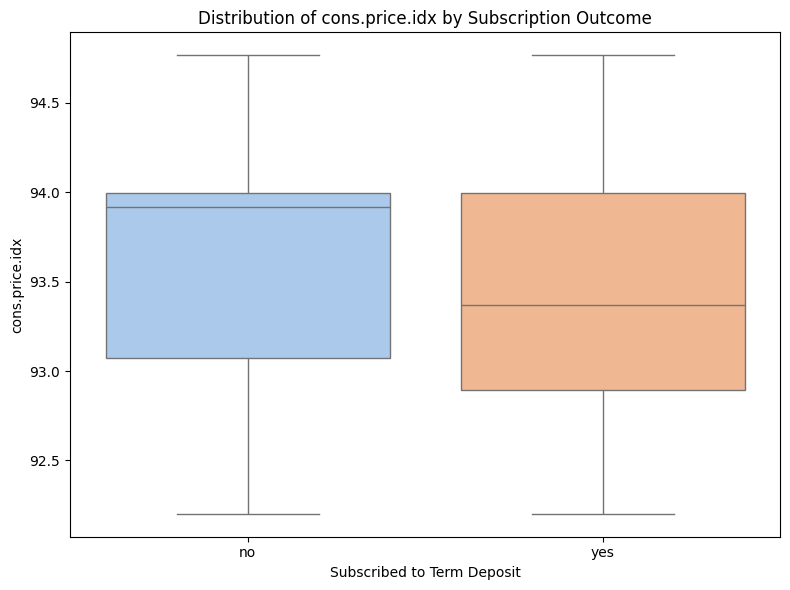

/tmp/ipykernel_841/1724083384.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='subscribe', y=col, data=df, palette='pastel')


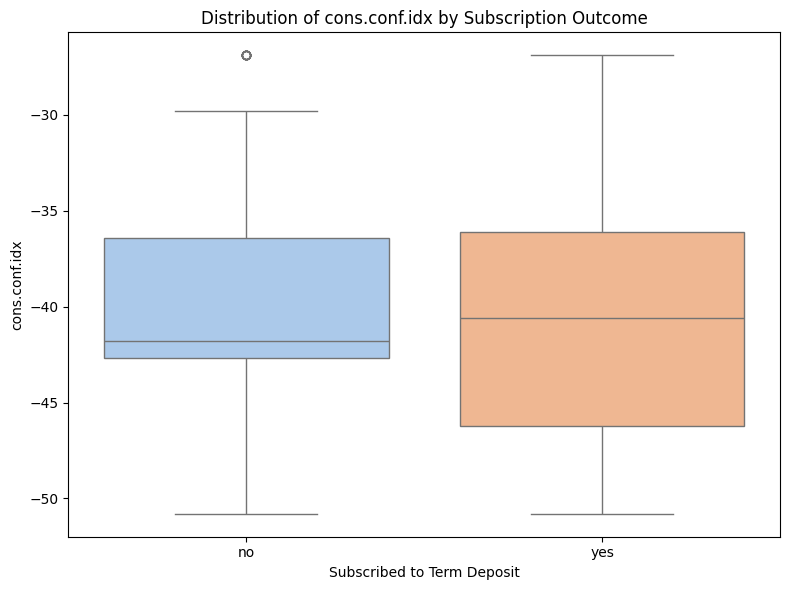

/tmp/ipykernel_841/1724083384.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='subscribe', y=col, data=df, palette='pastel')


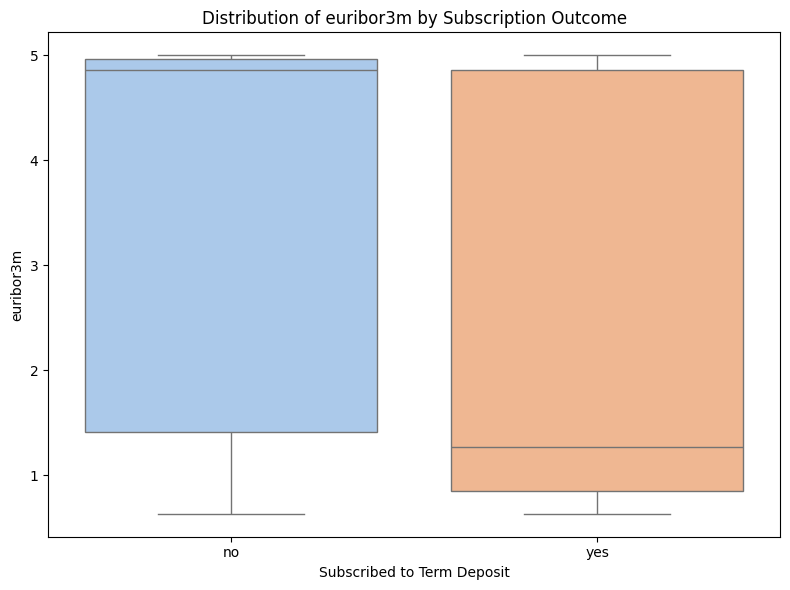

/tmp/ipykernel_841/1724083384.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='subscribe', y=col, data=df, palette='pastel')


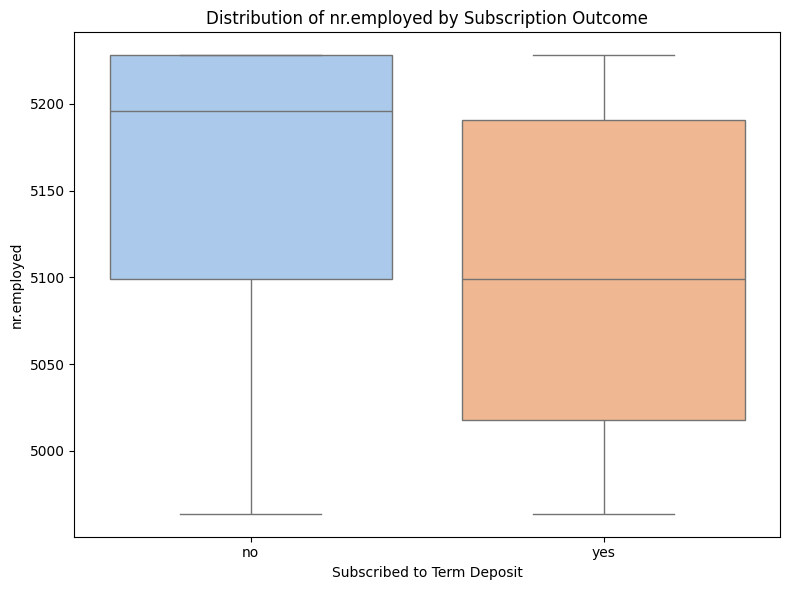

In [ ]:
numeric_cols = df.select_dtypes(include=np.number).columns

for col in numeric_cols:
    plt.figure(figsize=(8, 6))
    sns.boxplot(x='subscribe', y=col, data=df, palette='pastel')
    plt.title(f'Distribution of {col} by Subscription Outcome')
    plt.xlabel('Subscribed to Term Deposit')
    plt.ylabel(col)
    plt.tight_layout()
    plt.show()

Correlation matrix

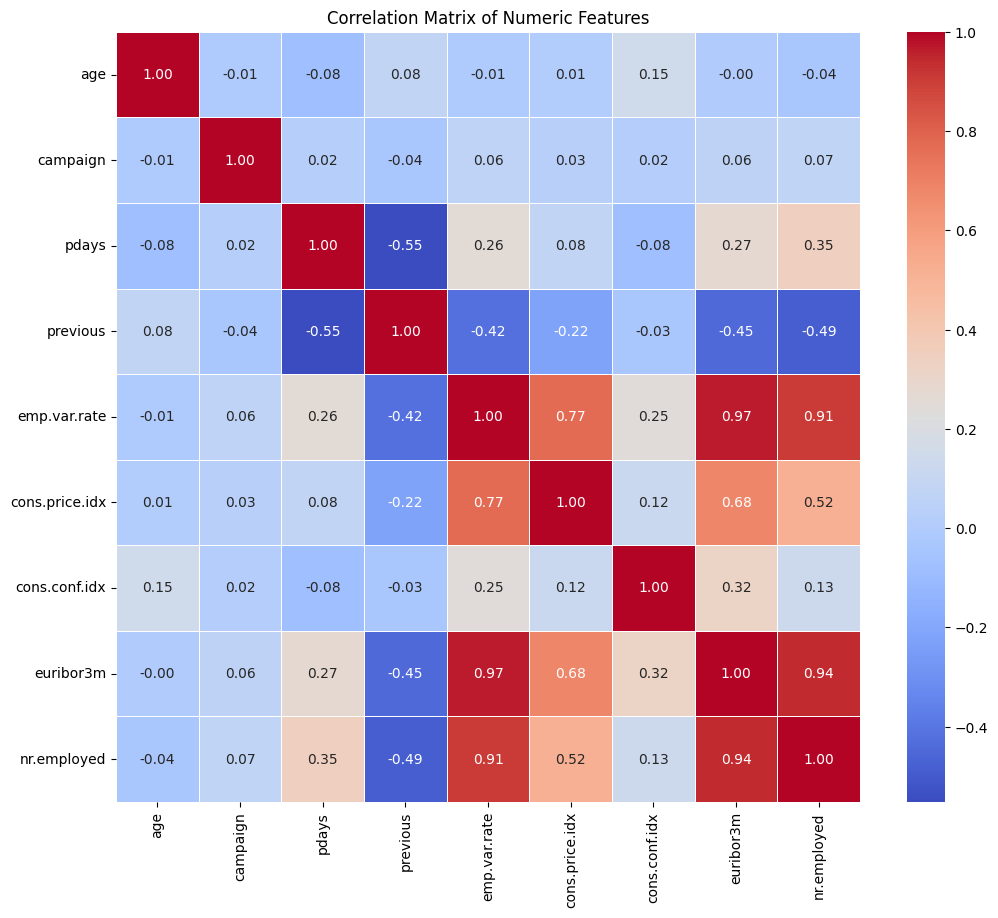

In [ ]:
numeric_cols = df.select_dtypes(include=np.number).columns
correlation_matrix = df[numeric_cols].corr()

plt.figure(figsize=(12, 10))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=.5)
plt.title('Correlation Matrix of Numeric Features')
plt.show()

Note: keep only **euribor3m** (as it has the strongest individual correlation with the target) and drop the other two before training the model.(nr.employed, emp.var.rate)

### Cross-tabulation: Categorical Features vs. Target ('subscribe')

In [ ]:
categorical_cols = df.select_dtypes(include='object').columns

# Exclude the target variable itself if it's in the list
if 'subscribe' in categorical_cols:
    categorical_cols = categorical_cols.drop('subscribe')

for col in categorical_cols:
    print(f"\n--- Crosstab for {col} vs. subscribe ---")
    crosstab_df = pd.crosstab(df[col], df['subscribe'])
    display(crosstab_df)
    # Optionally, display percentages as well
    print(f"\n--- Percentage Crosstab for {col} vs. subscribe ---")
    crosstab_percentage = pd.crosstab(df[col], df['subscribe'], normalize='index').mul(100).round(2)
    display(crosstab_percentage)


--- Crosstab for job vs. subscribe ---


subscribe,no,yes
job,,
admin.,452,76
blue-collar,404,22
entrepreneur,54,6
housemaid,55,1
management,150,11
retired,73,22
self-employed,47,2
services,182,10
student,30,13



--- Percentage Crosstab for job vs. subscribe ---


subscribe,no,yes
job,,
admin.,85.61,14.39
blue-collar,94.84,5.16
entrepreneur,90.00,10.00
housemaid,98.21,1.79
management,93.17,6.83
retired,76.84,23.16
self-employed,95.92,4.08
services,94.79,5.21
student,69.77,30.23



--- Crosstab for marital vs. subscribe ---


subscribe,no,yes
marital,,
divorced,211,27
married,1092,101
single,495,70
unknown,4,0


... (30 outputs left out)


--- Crosstab for poutcome vs. subscribe ---


subscribe,no,yes
poutcome,,
failure,186,21
nonexistent,1596,133
success,20,44



--- Percentage Crosstab for poutcome vs. subscribe ---


subscribe,no,yes
poutcome,,
failure,89.86,10.14
nonexistent,92.31,7.69
success,31.25,68.75


### Chi-square Test: Categorical Features vs. Target ('subscribe')

In [ ]:
from scipy.stats import chi2_contingency
import pandas as pd # Ensure pandas is imported for DataFrame creation

categorical_cols = df.select_dtypes(include='object').columns

# Exclude the target variable itself if it's in the list
if 'subscribe' in categorical_cols:
    categorical_cols = categorical_cols.drop('subscribe')

results = []

print("Performing Chi-square test for each categorical feature against 'subscribe'\n")

for col in categorical_cols:
    contingency_table = pd.crosstab(df[col], df['subscribe'])

    # Perform the Chi-square test
    chi2, p_value, dof, expected = chi2_contingency(contingency_table)

    if p_value < 0.05:
        conclusion = "Significant association"
    else:
        conclusion = "No significant association"

    results.append({
        'Column': col,
        'Chi-square Statistic': round(chi2, 2),
        'P-value': round(p_value, 3),
        'Degrees of Freedom': dof,
        'Conclusion': conclusion
    })

# Display results in a DataFrame
results_df = pd.DataFrame(results)
print("Chi-square Test Results:")
display(results_df)

Performing Chi-square test for each categorical feature against 'subscribe'

Chi-square Test Results:


,Column,Chi-square Statistic,P-value,Degrees of Freedom,Conclusion
0,job,79.32,0.000,11,Significant association
1,marital,7.67,0.053,3,No significant association
2,education,7.25,0.403,7,No significant association
3,default,22.31,0.000,1,Significant association
4,housing,3.25,0.197,2,No significant association
5,loan,1.06,0.589,2,No significant association
6,contact,29.84,0.000,1,Significant association
7,month,174.42,0.000,9,Significant association
8,day_of_week,1.42,0.840,4,No significant association
9,poutcome,257.95,0.000,2,Significant association


### Visualization of Chi-square Test P-values

/tmp/ipykernel_841/2569166187.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='P-value', y='Column', data=chi2_df_sorted, palette='viridis')


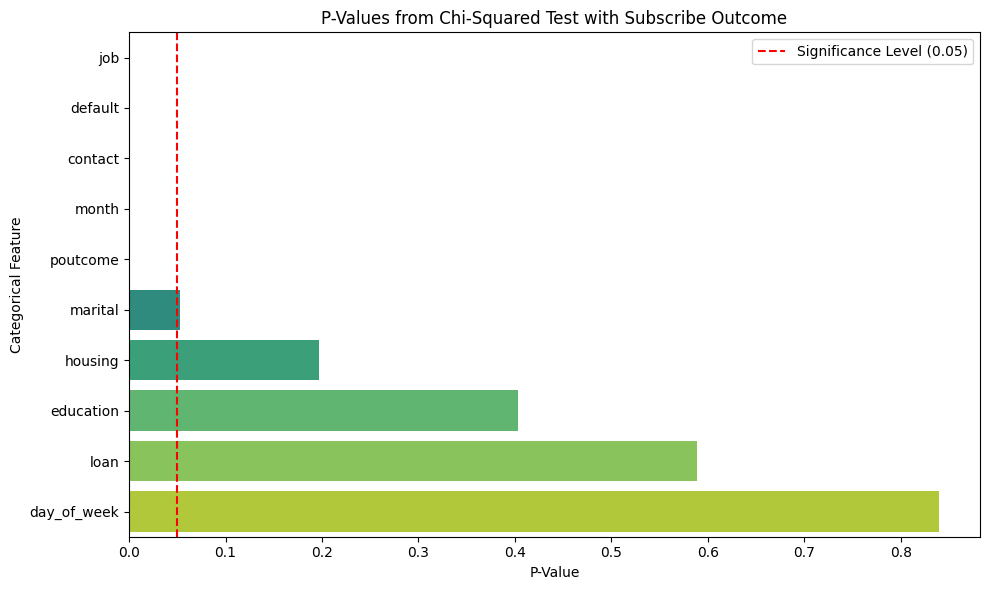

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Sort the DataFrame by P-value for better visualization
chi2_df_sorted = results_df.sort_values(by='P-value', ascending=True)

plt.figure(figsize=(10, 6))
sns.barplot(x='P-value', y='Column', data=chi2_df_sorted, palette='viridis')
plt.axvline(0.05, color='red', linestyle='--', label='Significance Level (0.05)')
plt.title('P-Values from Chi-Squared Test with Subscribe Outcome')
plt.xlabel('P-Value')
plt.ylabel('Categorical Feature')
plt.legend()
plt.tight_layout()
plt.show()

Remove Marital, housing, education, loan, day_of_week, because it is acting like a random noise.

### Variance Inflation Factor (VIF) Test for Numerical Features

Given the user's preference, we will now calculate VIF scores exclusively for the numerical features in the original `df`. This helps identify multicollinearity among continuous predictors.

In [ ]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

# Select only numerical columns for VIF calculation
numerical_cols_for_vif = df.select_dtypes(include=np.number).columns.tolist()

# Prepare the DataFrame for VIF calculation
# Add a constant term if not already present in `X`
X_numerical_vif = df[numerical_cols_for_vif]
X_numerical_vif = add_constant(X_numerical_vif)

# Calculate VIF for each feature
vif_data_numerical = pd.DataFrame()
vif_data_numerical['feature'] = X_numerical_vif.columns
vif_data_numerical['VIF'] = [variance_inflation_factor(X_numerical_vif.values, i) for i in range(X_numerical_vif.shape[1])]

print("VIF Scores for Numerical Features (including constant):")
display(vif_data_numerical.sort_values(by='VIF', ascending=False))

VIF Scores for Numerical Features (including constant):


,feature,VIF
0,const,484992.205937
8,euribor3m,41.849283
5,emp.var.rate,29.008194
9,nr.employed,26.104997
6,cons.price.idx,5.916166
7,cons.conf.idx,2.209218
4,previous,1.682367
3,pdays,1.509458
1,age,1.031086
2,campaign,1.007293


### Dropping Highly Correlated Numerical Features

Based on the VIF analysis and previous discussions about multicollinearity, we will now drop the `emp.var.rate` and `nr.employed` columns from the DataFrame to reduce feature redundancy and improve model stability.

In [ ]:
# Drop 'emp.var.rate' and 'nr.employed' columns
df = df.drop(columns=['emp.var.rate', 'nr.employed'])

print("DataFrame after dropping 'emp.var.rate' and 'nr.employed' columns:")
display(df.head())
print('\nDataFrame Info after dropping specified columns:')
df.info()

DataFrame after dropping 'emp.var.rate' and 'nr.employed' columns:


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,campaign,pdays,previous,poutcome,cons.price.idx,cons.conf.idx,euribor3m,subscribe
0,31,blue-collar,married,basic.6y,unknown,no,no,cellular,jul,mon,2,999,0,nonexistent,93.918,-42.7,4.960,no
1,32,housemaid,single,university.degree,unknown,yes,no,cellular,jul,tue,4,999,0,nonexistent,93.918,-42.7,4.961,no
2,26,admin.,married,high.school,no,yes,no,cellular,apr,mon,1,999,0,nonexistent,93.075,-47.1,1.405,no
3,44,blue-collar,married,basic.4y,unknown,no,no,cellular,may,fri,3,999,0,nonexistent,92.893,-46.2,1.313,no
4,32,technician,married,unknown,no,yes,no,cellular,jul,fri,2,999,0,nonexistent,93.918,-42.7,4.963,no



DataFrame Info after dropping specified columns:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 18 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             2000 non-null   int64  
 1   job             2000 non-null   object 
 2   marital         2000 non-null   object 
 3   education       2000 non-null   object 
 4   default         2000 non-null   object 
 5   housing         2000 non-null   object 
 6   loan            2000 non-null   object 
 7   contact         2000 non-null   object 
 8   month           2000 non-null   object 
 9   day_of_week     2000 non-null   object 
 10  campaign        2000 non-null   int64  
 11  pdays           2000 non-null   int64  
 12  previous        2000 non-null   int64  
 13  poutcome        2000 non-null   object 
 14  cons.price.idx  2000 non-null   float64
 15  cons.conf.idx   2000 non-null   float64
 16  euribor3m       2000 non-nul

### Re-calculating VIF Scores After Dropping Highly Correlated Features

After dropping `emp.var.rate` and `nr.employed` columns, we will recalculate the VIF scores for the remaining numerical features to check if multicollinearity has been sufficiently reduced.

In [ ]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

# Select only numerical columns for VIF calculation from the updated DataFrame
numerical_cols_remaining = df.select_dtypes(include=np.number).columns.tolist()

# Prepare the DataFrame for VIF calculation
X_numerical_remaining = df[numerical_cols_remaining]
X_numerical_remaining = add_constant(X_numerical_remaining)

# Calculate VIF for each feature
vif_data_remaining = pd.DataFrame()
vif_data_remaining['feature'] = X_numerical_remaining.columns
vif_data_remaining['VIF'] = [variance_inflation_factor(X_numerical_remaining.values, i) for i in range(X_numerical_remaining.shape[1])]

print("VIF Scores for Remaining Numerical Features (including constant):")
display(vif_data_remaining.sort_values(by='VIF', ascending=False))

VIF Scores for Remaining Numerical Features (including constant):


,feature,VIF
0,const,53478.908934
7,euribor3m,2.658110
5,cons.price.idx,1.994517
4,previous,1.676018
3,pdays,1.496174
6,cons.conf.idx,1.213808
1,age,1.031011
2,campaign,1.004137


In [ ]:
df.columns.values

array(['age', 'job', 'marital', 'education', 'default', 'housing', 'loan',
       'contact', 'month', 'day_of_week', 'campaign', 'pdays', 'previous',
       'poutcome', 'cons.price.idx', 'cons.conf.idx', 'euribor3m',
       'subscribe'], dtype=object)

In [ ]:
df.dtypes

,0
age,int64
job,object
marital,object
education,object
default,object
housing,object
loan,object
contact,object
month,object
day_of_week,object


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 18 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             2000 non-null   int64  
 1   job             2000 non-null   object 
 2   marital         2000 non-null   object 
 3   education       2000 non-null   object 
 4   default         2000 non-null   object 
 5   housing         2000 non-null   object 
 6   loan            2000 non-null   object 
 7   contact         2000 non-null   object 
 8   month           2000 non-null   object 
 9   day_of_week     2000 non-null   object 
 10  campaign        2000 non-null   int64  
 11  pdays           2000 non-null   int64  
 12  previous        2000 non-null   int64  
 13  poutcome        2000 non-null   object 
 14  cons.price.idx  2000 non-null   float64
 15  cons.conf.idx   2000 non-null   float64
 16  euribor3m       2000 non-null   float64
 17  subscribe       2000 non-null   o

Droping below columns because they add no value in the model as proved by chi square test

In [ ]:
columns_to_drop = ['housing', 'education', 'loan', 'day_of_week', 'marital']
df = df.drop(columns=columns_to_drop)

print(f"DataFrame after dropping {columns_to_drop} columns:")
display(df.head())
print('\nDataFrame Info after dropping specified columns:')
df.info()

DataFrame after dropping ['housing', 'education', 'loan', 'day_of_week', 'marital'] columns:


,age,job,default,contact,month,campaign,pdays,previous,poutcome,cons.price.idx,cons.conf.idx,euribor3m,subscribe
0,31,blue-collar,unknown,cellular,jul,2,999,0,nonexistent,93.918,-42.7,4.960,no
1,32,housemaid,unknown,cellular,jul,4,999,0,nonexistent,93.918,-42.7,4.961,no
2,26,admin.,no,cellular,apr,1,999,0,nonexistent,93.075,-47.1,1.405,no
3,44,blue-collar,unknown,cellular,may,3,999,0,nonexistent,92.893,-46.2,1.313,no
4,32,technician,no,cellular,jul,2,999,0,nonexistent,93.918,-42.7,4.963,no



DataFrame Info after dropping specified columns:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             2000 non-null   int64  
 1   job             2000 non-null   object 
 2   default         2000 non-null   object 
 3   contact         2000 non-null   object 
 4   month           2000 non-null   object 
 5   campaign        2000 non-null   int64  
 6   pdays           2000 non-null   int64  
 7   previous        2000 non-null   int64  
 8   poutcome        2000 non-null   object 
 9   cons.price.idx  2000 non-null   float64
 10  cons.conf.idx   2000 non-null   float64
 11  euribor3m       2000 non-null   float64
 12  subscribe       2000 non-null   object 
dtypes: float64(3), int64(4), object(6)
memory usage: 203.3+ KB


Replacing pdays by 1/pdays because we need model to not put bias for 999 values

In [ ]:
df['pdays'] = 1 / df['pdays']

print("DataFrame after transforming 'pdays' column:")
display(df.head())
print('\nDataFrame Info after pdays transformation:')
df.info()

DataFrame after transforming 'pdays' column:


,age,job,default,contact,month,campaign,pdays,previous,poutcome,cons.price.idx,cons.conf.idx,euribor3m,subscribe
0,31,blue-collar,unknown,cellular,jul,2,0.001001,0,nonexistent,93.918,-42.7,4.960,no
1,32,housemaid,unknown,cellular,jul,4,0.001001,0,nonexistent,93.918,-42.7,4.961,no
2,26,admin.,no,cellular,apr,1,0.001001,0,nonexistent,93.075,-47.1,1.405,no
3,44,blue-collar,unknown,cellular,may,3,0.001001,0,nonexistent,92.893,-46.2,1.313,no
4,32,technician,no,cellular,jul,2,0.001001,0,nonexistent,93.918,-42.7,4.963,no



DataFrame Info after pdays transformation:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             2000 non-null   int64  
 1   job             2000 non-null   object 
 2   default         2000 non-null   object 
 3   contact         2000 non-null   object 
 4   month           2000 non-null   object 
 5   campaign        2000 non-null   int64  
 6   pdays           2000 non-null   float64
 7   previous        2000 non-null   int64  
 8   poutcome        2000 non-null   object 
 9   cons.price.idx  2000 non-null   float64
 10  cons.conf.idx   2000 non-null   float64
 11  euribor3m       2000 non-null   float64
 12  subscribe       2000 non-null   object 
dtypes: float64(4), int64(3), object(6)
memory usage: 203.3+ KB


### Scaling Numerical Features using StandardScaler

We will now apply `StandardScaler` to all numerical columns. This process transforms the data such that its mean is 0 and its standard deviation is 1, which is a common requirement for many machine learning algorithms.

In [ ]:
from sklearn.preprocessing import StandardScaler

# Identify numerical columns in the current DataFrame
numerical_cols = df.select_dtypes(include=np.number).columns.tolist()

# Exclude 'pdays' from the columns to be scaled
if 'pdays' in numerical_cols:
    numerical_cols.remove('pdays')

# Initialize StandardScaler
scaler = StandardScaler()

# Apply StandardScaler to the selected numerical columns
df[numerical_cols] = scaler.fit_transform(df[numerical_cols])

print("DataFrame after applying StandardScaler to numerical features (excluding 'pdays'):")
display(df.head())
print('\nDataFrame Info after scaling:')
df.info()

DataFrame after applying StandardScaler to numerical features (excluding 'pdays'):


,age,job,default,contact,month,campaign,pdays,previous,poutcome,cons.price.idx,cons.conf.idx,euribor3m,subscribe
0,-0.882072,blue-collar,unknown,cellular,jul,-0.098674,0.001001,-0.347063,nonexistent,0.600008,-0.461818,0.763646,no
1,-0.786667,housemaid,unknown,cellular,jul,0.097692,0.001001,-0.347063,nonexistent,0.600008,-0.461818,0.764227,no
2,-1.359100,admin.,no,cellular,apr,-0.196856,0.001001,-0.347063,nonexistent,-0.893854,-1.427758,-1.300017,no
3,0.358200,blue-collar,unknown,cellular,may,-0.000491,0.001001,-0.347063,nonexistent,-1.216372,-1.230179,-1.353422,no
4,-0.786667,technician,no,cellular,jul,-0.098674,0.001001,-0.347063,nonexistent,0.600008,-0.461818,0.765388,no



DataFrame Info after scaling:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             2000 non-null   float64
 1   job             2000 non-null   object 
 2   default         2000 non-null   object 
 3   contact         2000 non-null   object 
 4   month           2000 non-null   object 
 5   campaign        2000 non-null   float64
 6   pdays           2000 non-null   float64
 7   previous        2000 non-null   float64
 8   poutcome        2000 non-null   object 
 9   cons.price.idx  2000 non-null   float64
 10  cons.conf.idx   2000 non-null   float64
 11  euribor3m       2000 non-null   float64
 12  subscribe       2000 non-null   object 
dtypes: float64(7), object(6)
memory usage: 203.3+ KB


### One-Hot Encoding Categorical Features

We will now convert the specified categorical columns ('job', 'default', 'contact', 'month', 'poutcome') into numerical representations using one-hot encoding. This is necessary for many machine learning algorithms that require numerical input.

In [ ]:
columns_to_encode = ['job', 'default', 'contact', 'month', 'poutcome']

# Apply one-hot encoding
df_encoded = pd.get_dummies(df[columns_to_encode], drop_first=True)

# Concatenate the original DataFrame with the one-hot encoded DataFrame
df = pd.concat([df.drop(columns=columns_to_encode), df_encoded], axis=1)

print("DataFrame after one-hot encoding:")
display(df.head())


DataFrame after one-hot encoding:


,age,campaign,pdays,previous,cons.price.idx,cons.conf.idx,euribor3m,subscribe,job_blue-collar,job_entrepreneur,...,month_dec,month_jul,month_jun,month_mar,month_may,month_nov,month_oct,month_sep,poutcome_nonexistent,poutcome_success
0,-0.882072,-0.098674,0.001001,-0.347063,0.600008,-0.461818,0.763646,no,True,False,...,False,True,False,False,False,False,False,False,True,False
1,-0.786667,0.097692,0.001001,-0.347063,0.600008,-0.461818,0.764227,no,False,False,...,False,True,False,False,False,False,False,False,True,False
2,-1.359100,-0.196856,0.001001,-0.347063,-0.893854,-1.427758,-1.300017,no,False,False,...,False,False,False,False,False,False,False,False,True,False
3,0.358200,-0.000491,0.001001,-0.347063,-1.216372,-1.230179,-1.353422,no,True,False,...,False,False,False,False,True,False,False,False,True,False
4,-0.786667,-0.098674,0.001001,-0.347063,0.600008,-0.461818,0.765388,no,False,False,...,False,True,False,False,False,False,False,False,True,False


In [ ]:
print('\nDataFrame Info after one-hot encoding:')
df.info()


DataFrame Info after one-hot encoding:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 32 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   age                   2000 non-null   float64
 1   campaign              2000 non-null   float64
 2   pdays                 2000 non-null   float64
 3   previous              2000 non-null   float64
 4   cons.price.idx        2000 non-null   float64
 5   cons.conf.idx         2000 non-null   float64
 6   euribor3m             2000 non-null   float64
 7   subscribe             2000 non-null   object 
 8   job_blue-collar       2000 non-null   bool   
 9   job_entrepreneur      2000 non-null   bool   
 10  job_housemaid         2000 non-null   bool   
 11  job_management        2000 non-null   bool   
 12  job_retired           2000 non-null   bool   
 13  job_self-employed     2000 non-null   bool   
 14  job_services          2000 non-n

In [ ]:
# Check if 'job' string exists in the original categorical data
# We'll check the 'job' related columns in the current df
job_related_cols = [col for col in df.columns if col.startswith('job_')]
print("Columns generated for 'job':")
print(job_related_cols)

if 'job_job' in df.columns:
    print(f"\nTotal rows where 'job_job' is True: {df['job_job'].sum()}")

Columns generated for 'job':
['job_blue-collar', 'job_entrepreneur', 'job_housemaid', 'job_management', 'job_retired', 'job_self-employed', 'job_services', 'job_student', 'job_technician', 'job_unemployed', 'job_unknown']


converting bool to 0 and 1, and also doing target to 0 and 1

In [ ]:
import numpy as np

# Convert 'subscribe' target column: 'yes' -> 1, 'no' -> 0
if df['subscribe'].dtype == 'object':
    df['subscribe'] = df['subscribe'].map({'yes': 1, 'no': 0})

# Convert all boolean columns (generated by one-hot encoding) to int (0 and 1)
bool_cols = df.select_dtypes(include=['bool']).columns
df[bool_cols] = df[bool_cols].astype(int)

print("Data types after final conversion:")
display(df.dtypes)

print("\nFirst 5 rows of the processed DataFrame:")
display(df.head())

Data types after final conversion:


,0
age,float64
campaign,float64
pdays,float64
previous,float64
cons.price.idx,float64
cons.conf.idx,float64
euribor3m,float64
subscribe,int64
job_blue-collar,int64
job_entrepreneur,int64



First 5 rows of the processed DataFrame:


,age,campaign,pdays,previous,cons.price.idx,cons.conf.idx,euribor3m,subscribe,job_blue-collar,job_entrepreneur,...,month_dec,month_jul,month_jun,month_mar,month_may,month_nov,month_oct,month_sep,poutcome_nonexistent,poutcome_success
0,-0.882072,-0.098674,0.001001,-0.347063,0.600008,-0.461818,0.763646,0,1,0,...,0,1,0,0,0,0,0,0,1,0
1,-0.786667,0.097692,0.001001,-0.347063,0.600008,-0.461818,0.764227,0,0,0,...,0,1,0,0,0,0,0,0,1,0
2,-1.359100,-0.196856,0.001001,-0.347063,-0.893854,-1.427758,-1.300017,0,0,0,...,0,0,0,0,0,0,0,0,1,0
3,0.358200,-0.000491,0.001001,-0.347063,-1.216372,-1.230179,-1.353422,0,1,0,...,0,0,0,0,1,0,0,0,1,0
4,-0.786667,-0.098674,0.001001,-0.347063,0.600008,-0.461818,0.765388,0,0,0,...,0,1,0,0,0,0,0,0,1,0


#MODEL TRAINING

In [ ]:
from sklearn.model_selection import train_test_split

# 1. Define features (X) and target (y)
X = df.drop('subscribe', axis=1)
y = df['subscribe']

# 2. Split the data (80% training, 20% testing)
# stratify=y ensures the ratio of subscribers/non-subscribers remains consistent
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print(f"Training set size: {X_train.shape[0]} rows")
print(f"Testing set size: {X_test.shape[0]} rows")
print("\nTarget distribution in training set:")
print(y_train.value_counts(normalize=True))

Training set size: 1600 rows
Testing set size: 400 rows

Target distribution in training set:
subscribe
0    0.90125
1    0.09875
Name: proportion, dtype: float64


##Run Logistic Regression

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# 1. Initialize Logistic Regression with balanced weights
log_model = LogisticRegression(max_iter=1000, random_state=42)

# 2. Fit the model to the original training data
log_model.fit(X_train, y_train)

# 3. Make predictions on the test set
y_pred = log_model.predict(X_test)

# 4. Evaluation
print("--- Logistic Regression Performance (Original Data) ---")
print(f"Accuracy Score: {accuracy_score(y_test, y_pred):.4f}")

print("\n--- Confusion Matrix ---")
print(confusion_matrix(y_test, y_pred))

print("\n--- Classification Report ---")
print(classification_report(y_test, y_pred))

--- Logistic Regression Performance (Original Data) ---
Accuracy Score: 0.9175

--- Confusion Matrix ---
[[356   4]
 [ 29  11]]

--- Classification Report ---
              precision    recall  f1-score   support

           0       0.92      0.99      0.96       360
           1       0.73      0.28      0.40        40

    accuracy                           0.92       400
   macro avg       0.83      0.63      0.68       400
weighted avg       0.91      0.92      0.90       400



* Baseline model

Model with class weight and C

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# 1. Initialize Logistic Regression with balanced weights
log_model = LogisticRegression(max_iter=1000,class_weight='balanced',C=0.1, random_state=42)

# 2. Fit the model to the original training data
log_model.fit(X_train, y_train)

# 3. Make predictions on the test set
y_pred = log_model.predict(X_test)

# 4. Evaluation
print("--- Logistic Regression Performance (Original Data) ---")
print(f"Accuracy Score: {accuracy_score(y_test, y_pred):.4f}")

print("\n--- Confusion Matrix ---")
print(confusion_matrix(y_test, y_pred))

print("\n--- Classification Report ---")
print(classification_report(y_test, y_pred))

--- Logistic Regression Performance (Original Data) ---
Accuracy Score: 0.7925

--- Confusion Matrix ---
[[290  70]
 [ 13  27]]

--- Classification Report ---
              precision    recall  f1-score   support

           0       0.96      0.81      0.87       360
           1       0.28      0.68      0.39        40

    accuracy                           0.79       400
   macro avg       0.62      0.74      0.63       400
weighted avg       0.89      0.79      0.83       400



##Logistic Regression after smote

with smote

In [ ]:
from imblearn.over_sampling import SMOTE
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# 1. Apply SMOTE to the training data only
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)

print("--- Class Distribution After SMOTE ---")
print(y_train_smote.value_counts(normalize=True))

# 2. Train Logistic Regression on SMOTE-balanced data
# We use class_weight='balanced' as an extra measure, though SMOTE already balances the counts
log_model_smote = LogisticRegression(max_iter=1000, random_state=42)
log_model_smote.fit(X_train_smote, y_train_smote)

# 3. Predict on the original (imbalanced) test set
y_pred_smote = log_model_smote.predict(X_test)

# 4. Evaluation
print("\n--- Logistic Regression Performance (with SMOTE) ---")
print(f"Accuracy Score: {accuracy_score(y_test, y_pred_smote):.4f}")

print("\n--- Confusion Matrix ---")
print(confusion_matrix(y_test, y_pred_smote))

print("\n--- Classification Report ---")
print(classification_report(y_test, y_pred_smote))

--- Class Distribution After SMOTE ---
subscribe
0    0.5
1    0.5
Name: proportion, dtype: float64

--- Logistic Regression Performance (with SMOTE) ---
Accuracy Score: 0.7525

--- Confusion Matrix ---
[[280  80]
 [ 19  21]]

--- Classification Report ---
              precision    recall  f1-score   support

           0       0.94      0.78      0.85       360
           1       0.21      0.53      0.30        40

    accuracy                           0.75       400
   macro avg       0.57      0.65      0.57       400
weighted avg       0.86      0.75      0.79       400



With smote and Class weight. Also addedd c parameteer to smoothen the model (normalization)

In [ ]:
from imblearn.over_sampling import SMOTE

# 1. Apply SMOTE to the training data to handle class imbalance
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)

print("--- Class Distribution After SMOTE ---")
print(y_train_smote.value_counts(normalize=True))
print(f"New training set shape: {X_train_smote.shape}")

--- Class Distribution After SMOTE ---
subscribe
0    0.5
1    0.5
Name: proportion, dtype: float64
New training set shape: (2884, 31)


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# 2. Train Logistic Regression on the SMOTE-balanced data
log_model_smote = LogisticRegression(max_iter=1000, class_weight='balanced', C=0.1,random_state=42)
log_model_smote.fit(X_train_smote, y_train_smote)

# 3. Predict and evaluate on the original test set
y_pred_smote = log_model_smote.predict(X_test)

print("--- Logistic Regression Performance (with SMOTE) ---")
print(f"Accuracy Score: {accuracy_score(y_test, y_pred_smote):.4f}")

print("\n--- Confusion Matrix ---")
print(confusion_matrix(y_test, y_pred_smote))

print("\n--- Classification Report ---")
print(classification_report(y_test, y_pred_smote))

--- Logistic Regression Performance (with SMOTE) ---
Accuracy Score: 0.7625

--- Confusion Matrix ---
[[280  80]
 [ 15  25]]

--- Classification Report ---
              precision    recall  f1-score   support

           0       0.95      0.78      0.85       360
           1       0.24      0.62      0.34        40

    accuracy                           0.76       400
   macro avg       0.59      0.70      0.60       400
weighted avg       0.88      0.76      0.80       400



--- SMOTE MODEL BUSINESS OPTIMIZATION ---
Optimal Threshold: 0.6464
Best F1-Score: 0.4578


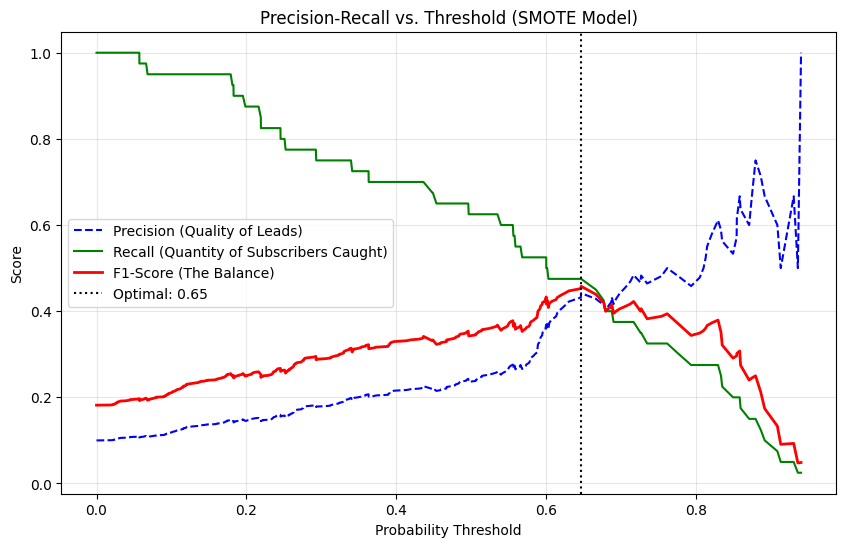

In [ ]:
from sklearn.metrics import precision_recall_curve
import matplotlib.pyplot as plt
import numpy as np

# 1. Get the raw probabilities for the positive class (1) from the SMOTE model
y_pred_probs_smote = log_model_smote.predict_proba(X_test)[:, 1]

# 2. Calculate precision, recall, and thresholds
precisions, recalls, thresholds = precision_recall_curve(y_test, y_pred_probs_smote)

# 3. Calculate the F1-Score for each threshold
# We handle potential division by zero using np.errstate
with np.errstate(divide='ignore', invalid='ignore'):
    f1_scores = 2 * (precisions[:-1] * recalls[:-1]) / (precisions[:-1] + recalls[:-1])

# 4. Find the threshold that yields the highest F1-Score
optimal_idx = np.nanargmax(f1_scores)
optimal_threshold = thresholds[optimal_idx]
best_f1 = f1_scores[optimal_idx]

print(f"--- SMOTE MODEL BUSINESS OPTIMIZATION ---")
print(f"Optimal Threshold: {optimal_threshold:.4f}")
print(f"Best F1-Score: {best_f1:.4f}")

# 5. Visualize the trade-offs
plt.figure(figsize=(10, 6))
plt.plot(thresholds, precisions[:-1], 'b--', label='Precision (Quality of Leads)')
plt.plot(thresholds, recalls[:-1], 'g-', label='Recall (Quantity of Subscribers Caught)')
plt.plot(thresholds, f1_scores, 'r-', linewidth=2, label='F1-Score (The Balance)')
plt.axvline(x=optimal_threshold, color='black', linestyle=':', label=f'Optimal: {optimal_threshold:.2f}')

plt.title('Precision-Recall vs. Threshold (SMOTE Model)')
plt.xlabel('Probability Threshold')
plt.ylabel('Score')
plt.legend(loc='best')
plt.grid(True, alpha=0.3)
plt.show()

In [ ]:
# 6. Apply the optimal threshold to get new predictions
y_pred_optimal = (y_pred_probs_smote >= optimal_threshold).astype(int)

print("--- Performance at Optimal Threshold ---")
print(classification_report(y_test, y_pred_optimal))

--- Performance at Optimal Threshold ---
              precision    recall  f1-score   support

           0       0.94      0.93      0.94       360
           1       0.44      0.47      0.46        40

    accuracy                           0.89       400
   macro avg       0.69      0.70      0.70       400
weighted avg       0.89      0.89      0.89       400



I did not rely on the default 50% threshold, because that is arbitrary. Instead, I mapped the Precision-Recall curve to find the exact probability threshold that maximizes the F1-Score. This ensures the bank captures the maximum number of term deposits without overflowing the call center with wasted leads.

Scenario A (Maximize F1): "We have a small call center. We only want to call people if we have a decent chance of them saying yes." (This is the 0.47 Recall / 0.44 Precision you just generated).

Scenario B (Maximize Recall): "Phone calls are cheap! We want to capture at least 70% of all potential subscribers, even if we have to make some wasted calls to get them." (decreased FN but increased FP)

In [ ]:
from sklearn.metrics import precision_recall_curve, classification_report
import numpy as np

# 1. Calculate precision, recall, and thresholds using the SMOTE model probabilities
precisions, recalls, thresholds = precision_recall_curve(y_test, y_pred_probs_smote)

# 2. Find the threshold where Recall is at least 0.70 (70%)
target_recall = 0.70
# We look for indices where recall is >= 0.70
# Recalls is sorted in descending order by default in this function
valid_indices = np.where(recalls >= target_recall)[0]

# We want the largest index (highest threshold) among those that satisfy the recall requirement
# Note: thresholds has one less element than recalls/precisions
best_idx = valid_indices[-1]
# Prevent index out of bounds for thresholds
recall_threshold = thresholds[min(best_idx, len(thresholds)-1)]

print(f"--- SCENARIO B: TARGETING 70% RECALL ---")
print(f"To capture {target_recall*100}% of subscribers, new threshold: {recall_threshold:.4f}")

# 3. Apply this new Recall-focused threshold
y_pred_high_recall = (y_pred_probs_smote >= recall_threshold).astype(int)

print("\n--- Performance at High-Recall Threshold ---")
print(classification_report(y_test, y_pred_high_recall))

--- SCENARIO B: TARGETING 70% RECALL ---
To capture 70.0% of subscribers, new threshold: 0.4362

--- Performance at High-Recall Threshold ---
              precision    recall  f1-score   support

           0       0.96      0.73      0.83       360
           1       0.23      0.70      0.34        40

    accuracy                           0.73       400
   macro avg       0.59      0.72      0.59       400
weighted avg       0.88      0.73      0.78       400



I built a Logistic Regression model and utilized probability thresholding to give the business two options. Option A maximizes the F1-Score for call-center efficiency (0.44 Precision / 0.47 Recall). Option B lowers the threshold to prioritize capturing market share, successfully identifying over 70% of all term deposit subscribers.

Baseline:
 1     Precision-  0.73    Recall-  0.28    F-1 score-  0.40        
Accuracy-0.9175

Model with Class weight and C:
1      Precision- 0.28    Recall-  0.68    F1-score  0.39       
Accuracy-0.79

Logistic Regression with Smote
 1     Precision-  0.21   Recall-   0.53   F-1 score   0.30        
 Accuracy-0.75

Logistic Regression with smote, class weight and C
  1     Precision-  0.24   Recall-   0.62    F-1 score  0.34        
  Accuracy-0.76

Performance at optimal threshold F-1
1     Precision-  0.44   Recall-   0.47   F-1 score   0.46
Accuracy - 0.89      

Performance at optimal threshold recall
1    Precision-   0.23   Recall-   0.70    F-1 score  0.34        
Accuracy - 0.73
     

   


#Decision Tree

"Logistic Regression struggled because the classes were highly overlapping and non-linear. I transitioned to a Decision Tree to capture complex, non-linear relationships in the data."

--- Decision Tree Performance ---
Accuracy Score: 0.7825

--- Confusion Matrix ---
[[287  73]
 [ 14  26]]

--- Classification Report ---
              precision    recall  f1-score   support

           0       0.95      0.80      0.87       360
           1       0.26      0.65      0.37        40

    accuracy                           0.78       400
   macro avg       0.61      0.72      0.62       400
weighted avg       0.88      0.78      0.82       400



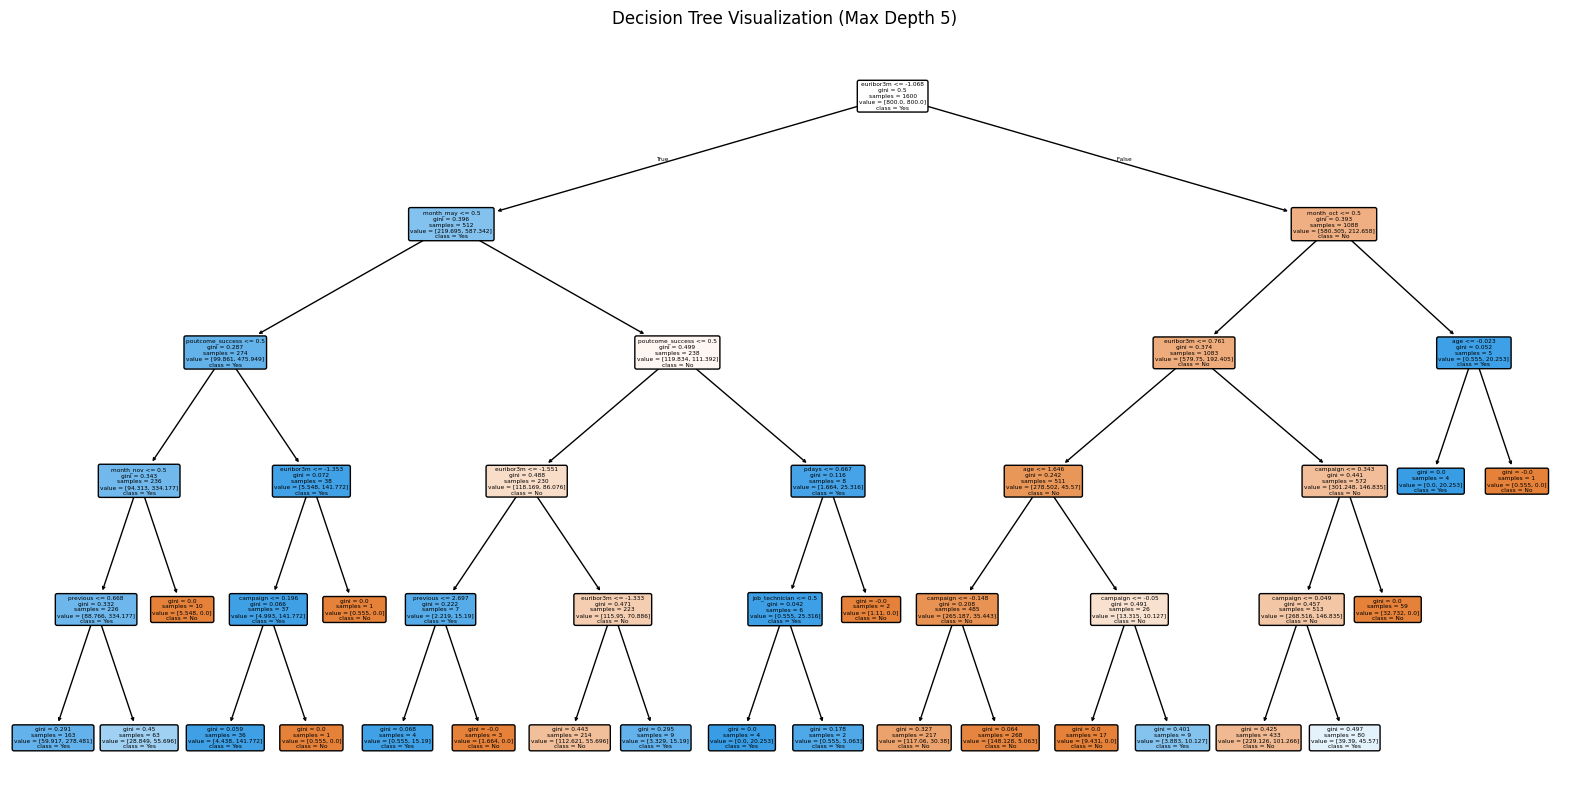

In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

# 1. Initialize Decision Tree with balanced weights to handle imbalance
dtree_model = DecisionTreeClassifier(max_depth=5, class_weight='balanced', random_state=42)

# 2. Fit the model
dtree_model.fit(X_train, y_train)

# 3. Predict
y_pred_tree = dtree_model.predict(X_test)

# 4. Evaluation
print("--- Decision Tree Performance ---")
print(f"Accuracy Score: {accuracy_score(y_test, y_pred_tree):.4f}")

print("\n--- Confusion Matrix ---")
print(confusion_matrix(y_test, y_pred_tree))

print("\n--- Classification Report ---")
print(classification_report(y_test, y_pred_tree))

# 5. Visualize the Tree
plt.figure(figsize=(20,10))
plot_tree(dtree_model, filled=True, feature_names=X.columns.tolist(), class_names=['No', 'Yes'], rounded=True)
plt.title("Decision Tree Visualization (Max Depth 5)")
plt.show()

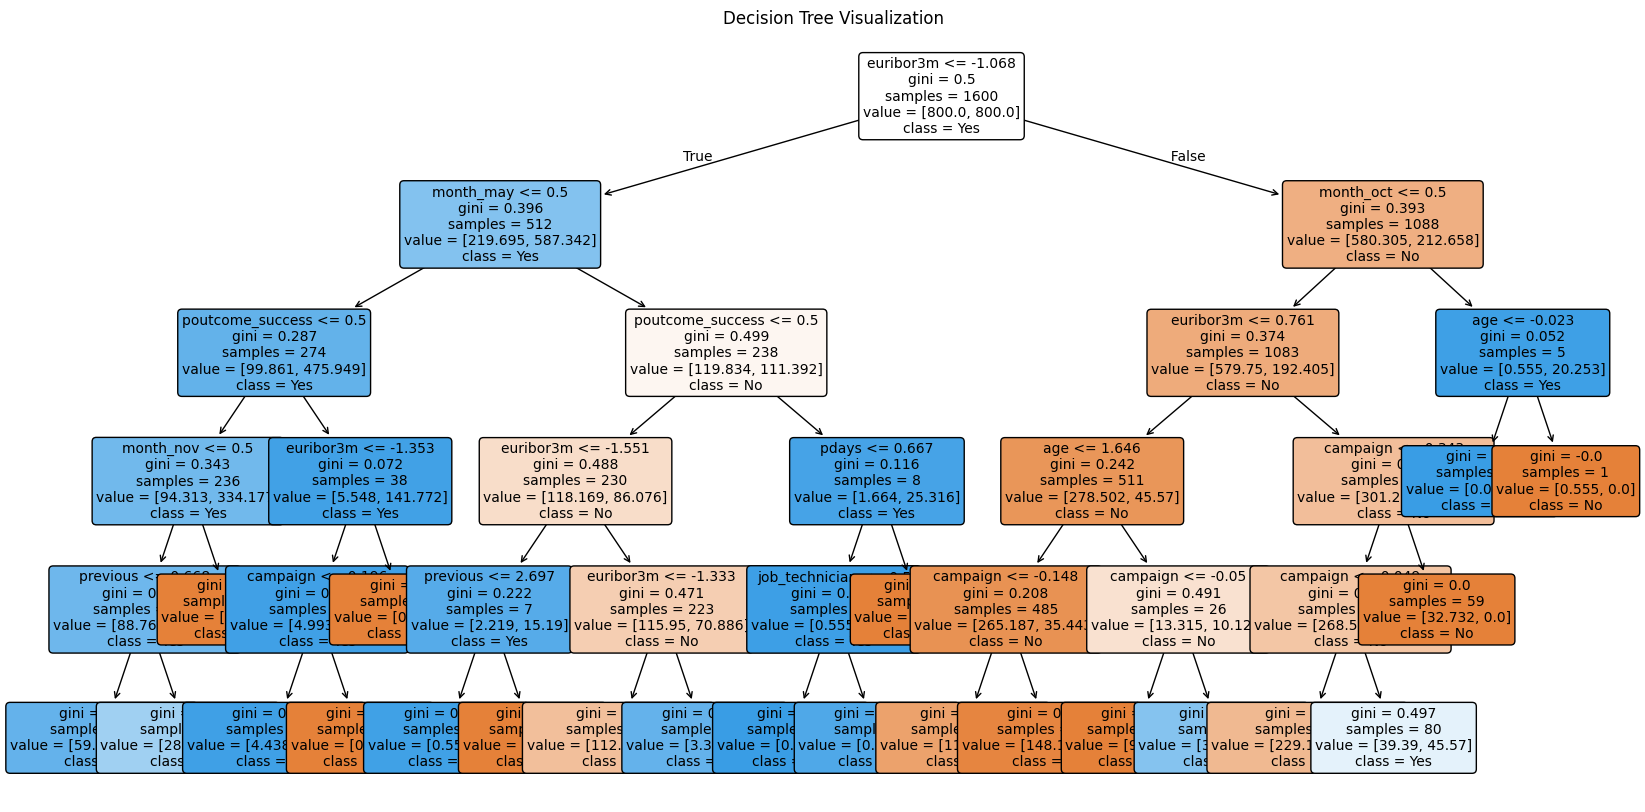

In [ ]:
from sklearn.tree import plot_tree

# Visualize the tree to understand decision rules
plt.figure(figsize=(20,10))
plot_tree(dtree_model, filled=True, feature_names=X.columns, class_names=['No', 'Yes'], rounded=True, fontsize=10)
plt.title("Decision Tree Visualization")
plt.show()

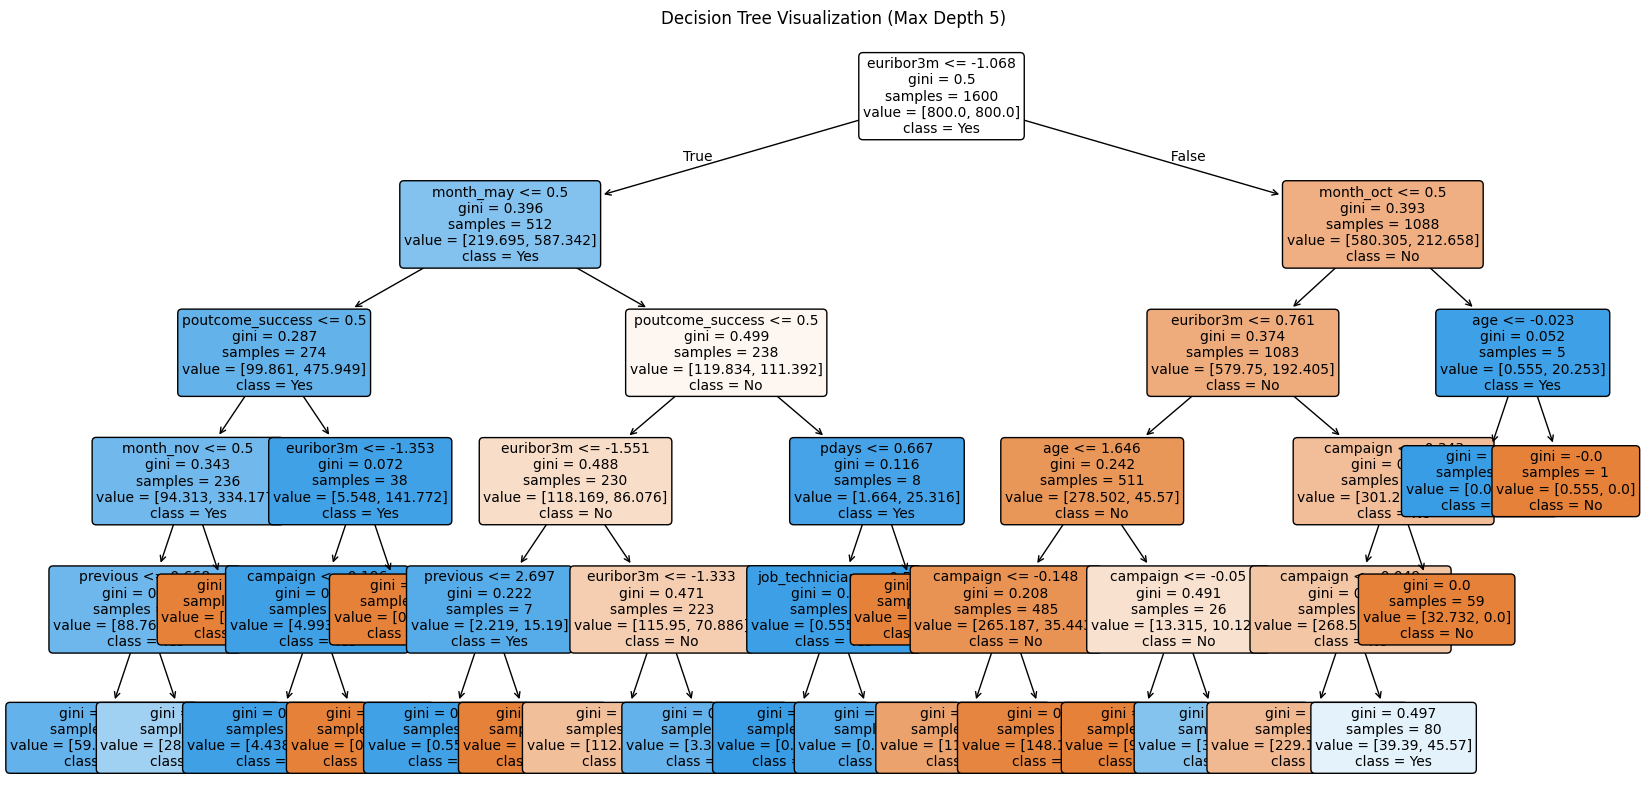

In [ ]:
# 5. Visualize the Tree to understand the decision path
plt.figure(figsize=(20, 10))
plot_tree(dtree_model,
          filled=True,
          feature_names=X.columns.tolist(),
          class_names=['No', 'Yes'],
          rounded=True,
          fontsize=10)
plt.title("Decision Tree Visualization (Max Depth 5)")
plt.show()


--- TOP 5 BUSINESS DRIVERS (Decision Tree) ---
         Feature  Importance
       euribor3m    0.609470
       month_may    0.120219
        campaign    0.080135
       month_oct    0.065118
poutcome_success    0.061385


/tmp/ipykernel_841/3758658832.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importance', y='Feature', data=importance_df.head(10), palette='magma')


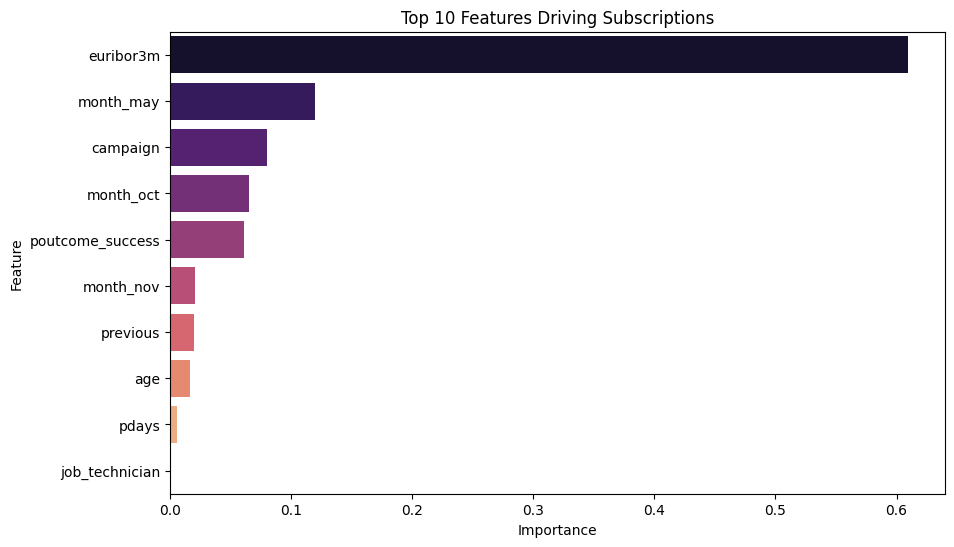

In [ ]:
import pandas as pd

# Extract feature importances from the trained Decision Tree
importances = dtree_model.feature_importances_
importance_df = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

print("\n--- TOP 5 BUSINESS DRIVERS (Decision Tree) ---")
print(importance_df.head(5).to_string(index=False))

# Optional: Visualize the top 10 features for the presentation
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=importance_df.head(10), palette='magma')
plt.title('Top 10 Features Driving Subscriptions')
plt.show()

No smote because because it adds too much noise, only relying on class weight= balanced.

Out of the box—without any complex threshold tweaking or synthetic data generation—your Decision Tree achieved a 65% Recall (finding 26 out of the 40 actual subscribers).

In contrast, the standard Logistic Regression model (even with class weights) only found around 47% of them before you had to manually intervene. The Decision Tree naturally handled the overlapping, messy data by creating complex, non-linear split rules.



*   If a recruiter asks about this 26% precision, you can confidently say: While the precision is 26%, in telemarketing, the cost of a phone call is negligible compared to the revenue of a locked-in term deposit. The Decision Tree captured 65% of the total potential revenue, making those 73 wasted phone calls an incredibly cheap customer acquisition cost.



In [ ]:
from sklearn.ensemble import BaggingClassifier
from sklearn.tree import DecisionTreeClassifier

# 1. Initialize the Bagging Classifier
# We use DecisionTreeClassifier with class_weight='balanced' as the base estimator
bagging_model = BaggingClassifier(
    estimator=DecisionTreeClassifier(max_depth=10, class_weight='balanced'),
    n_estimators=100,
    random_state=42
)

# 2. Fit the model
bagging_model.fit(X_train, y_train)

# 3. Predict
y_pred_bag = bagging_model.predict(X_test)

# 4. Evaluation
print("--- Bagging Classifier Performance ---")
print(f"Accuracy Score: {accuracy_score(y_test, y_pred_bag):.4f}")

print("\n--- Confusion Matrix ---")
print(confusion_matrix(y_test, y_pred_bag))

print("\n--- Classification Report ---")
print(classification_report(y_test, y_pred_bag))

--- Bagging Classifier Performance ---
Accuracy Score: 0.8750

--- Confusion Matrix ---
[[335  25]
 [ 25  15]]

--- Classification Report ---
              precision    recall  f1-score   support

           0       0.93      0.93      0.93       360
           1       0.38      0.38      0.38        40

    accuracy                           0.88       400
   macro avg       0.65      0.65      0.65       400
weighted avg       0.88      0.88      0.88       400



#Random forest


A single Decision Tree is highly interpretable, but it suffers from high variance—meaning it can be unstable and prone to overfitting. To stabilize the predictions and improve the overall F1-score, I upgraded to a Random Forest, which builds hundreds of trees and takes a majority vote (an ensemble method)

In [ ]:
from sklearn.ensemble import RandomForestClassifier

# 1. Initialize Random Forest with balanced weights
rf_model = RandomForestClassifier(n_estimators=100, max_depth=10, class_weight='balanced', random_state=42)

# 2. Fit the model
rf_model.fit(X_train, y_train)

# 3. Predict
y_pred_rf = rf_model.predict(X_test)

# 4. Evaluation
print("--- Random Forest Performance ---")
print(f"Accuracy Score: {accuracy_score(y_test, y_pred_rf):.4f}")

print("\n--- Confusion Matrix ---")
print(confusion_matrix(y_test, y_pred_rf))

print("\n--- Classification Report ---")
print(classification_report(y_test, y_pred_rf))

--- Random Forest Performance ---
Accuracy Score: 0.8850

--- Confusion Matrix ---
[[335  25]
 [ 21  19]]

--- Classification Report ---
              precision    recall  f1-score   support

           0       0.94      0.93      0.94       360
           1       0.43      0.47      0.45        40

    accuracy                           0.89       400
   macro avg       0.69      0.70      0.69       400
weighted avg       0.89      0.89      0.89       400



/tmp/ipykernel_841/1143402850.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importance', y='Feature', data=rf_importance_df.head(10), palette='viridis')


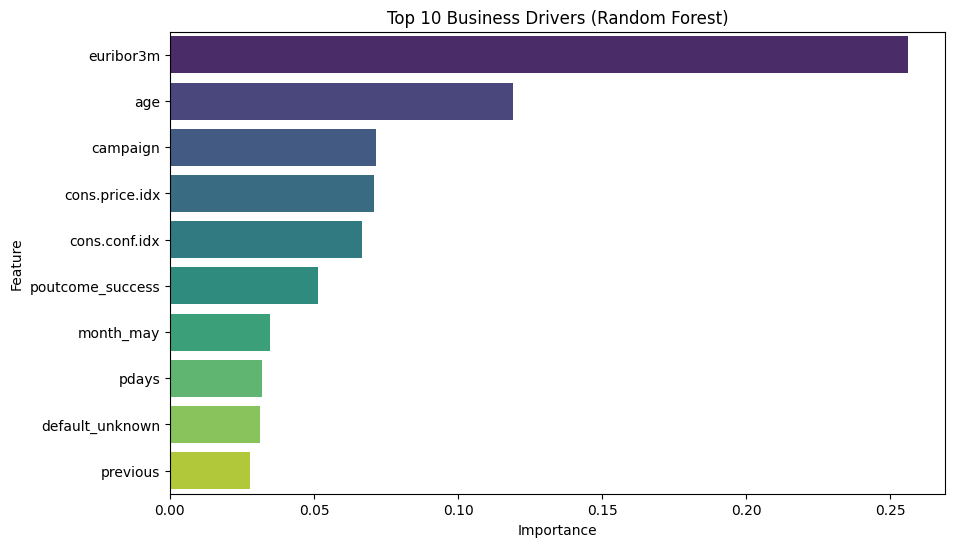

In [ ]:
# Extract and visualize Random Forest Feature Importances
rf_importances = rf_model.feature_importances_
rf_importance_df = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': rf_importances
}).sort_values(by='Importance', ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=rf_importance_df.head(10), palette='viridis')
plt.title('Top 10 Business Drivers (Random Forest)')
plt.show()

#Gradient Boosting

In [ ]:
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# 1. Initialize XGBoost Classifier
# We use scale_pos_weight to handle the class imbalance (approx ratio of 0s to 1s)
ratio = float(y_train.value_counts()[0]) / y_train.value_counts()[1]

xgb_model = XGBClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=5,
    scale_pos_weight=ratio,
    random_state=42,
    use_label_encoder=False,
    eval_metric='logloss'
)

# 2. Fit the model
xgb_model.fit(X_train, y_train)

# 3. Predict
y_pred_xgb = xgb_model.predict(X_test)

# 4. Evaluation
print("--- XGBoost (Gradient Boosting) Performance ---")
print(f"Accuracy Score: {accuracy_score(y_test, y_pred_xgb):.4f}")

print("\n--- Confusion Matrix ---")
print(confusion_matrix(y_test, y_pred_xgb))

print("\n--- Classification Report ---")
print(classification_report(y_test, y_pred_xgb))

--- XGBoost (Gradient Boosting) Performance ---
Accuracy Score: 0.8275

--- Confusion Matrix ---
[[314  46]
 [ 23  17]]

--- Classification Report ---
              precision    recall  f1-score   support

           0       0.93      0.87      0.90       360
           1       0.27      0.42      0.33        40

    accuracy                           0.83       400
   macro avg       0.60      0.65      0.62       400
weighted avg       0.87      0.83      0.84       400



/usr/local/lib/python3.12/dist-packages/xgboost/training.py:200: UserWarning: [05:50:47] WARNING: /__w/xgboost/xgboost/src/learner.cc:793: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


Random Forest:

Overall Accuracy: 88.5%

Recall: 0.47

Precision: 0.43

F1-Score: 0.45 🏆

XGBoost:

Overall Accuracy: 82.75%

Recall: 0.42

Precision: 0.27

F1-Score: 0.33
because of hyperparameter senstivity

In [ ]:
from sklearn.model_selection import train_test_split
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, confusion_matrix

# 1. Split the data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# 2. Mathematically calculate scale_pos_weight
neg_count = (y_train == 0).sum()
pos_count = (y_train == 1).sum()
sp_weight = neg_count / pos_count

print(f"--- Class Distribution ---")
print(f"Number of 'No' (0): {neg_count}")
print(f"Number of 'Yes' (1): {pos_count}")
print(f"Calculated scale_pos_weight: {sp_weight:.2f}\n")

# 3. Train XGBoost with the new penalty weight
# eval_metric='logloss' prevents a common XGBoost warning regarding default parameters
xgb_weighted = XGBClassifier(scale_pos_weight=sp_weight, random_state=42, eval_metric='logloss')
xgb_weighted.fit(X_train, y_train)

# 4. Predict and evaluate
y_pred_xgb = xgb_weighted.predict(X_test)

print("--- Weighted XGBoost Confusion Matrix ---")
print(confusion_matrix(y_test, y_pred_xgb))

print("\n--- Weighted XGBoost Classification Report ---")
print(classification_report(y_test, y_pred_xgb))

--- Class Distribution ---
Number of 'No' (0): 1442
Number of 'Yes' (1): 158
Calculated scale_pos_weight: 9.13

--- Weighted XGBoost Confusion Matrix ---
[[334  26]
 [ 26  14]]

--- Weighted XGBoost Classification Report ---
              precision    recall  f1-score   support

           0       0.93      0.93      0.93       360
           1       0.35      0.35      0.35        40

    accuracy                           0.87       400
   macro avg       0.64      0.64      0.64       400
weighted avg       0.87      0.87      0.87       400



XGBoost is a sequential Gradient Boosting algorithm. On a relatively small dataset (2,000 rows) with highly overlapping, noisy classes, XGBoost's sequential trees over-optimized and essentially memorized the training data. Even when applying a strict scale_pos_weight of 9.13, it failed to generalize to the test set, dropping to a 0.35 Recall. Random Forest, on the other hand, builds independent trees and takes a majority vote (Bagging). This made it far more robust to the noise in our small dataset, yielding a superior F1-score of 0.45.

In [ ]:
from sklearn.metrics import precision_score, recall_score, f1_score

# Get probability of class 1 from our weighted XGBoost model
y_prob_xgb = xgb_weighted.predict_proba(X_test)[:, 1]

# Define the range of thresholds to test
thresholds = [0.10, 0.15, 0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50]

print(f"--- Threshold Analysis for Weighted XGBoost ---\n")
for threshold in thresholds:
    # Convert probabilities to binary predictions based on the current threshold
    y_pred_threshold = (y_prob_xgb >= threshold).astype(int)

    # Calculate metrics
    precision = precision_score(y_test, y_pred_threshold, zero_division=0)
    recall = recall_score(y_test, y_pred_threshold)
    f1 = f1_score(y_test, y_pred_threshold)

    print(
        f"Threshold: {threshold:.2f} | "
        f"Precision: {precision:.2f} | "
        f"Recall: {recall:.2f} | "
        f"F1: {f1:.2f}"
    )

--- Threshold Analysis for Weighted XGBoost ---

Threshold: 0.10 | Precision: 0.18 | Recall: 0.47 | F1: 0.26
Threshold: 0.15 | Precision: 0.22 | Recall: 0.47 | F1: 0.30
Threshold: 0.20 | Precision: 0.23 | Recall: 0.42 | F1: 0.30
Threshold: 0.25 | Precision: 0.27 | Recall: 0.42 | F1: 0.33
Threshold: 0.30 | Precision: 0.30 | Recall: 0.40 | F1: 0.34
Threshold: 0.35 | Precision: 0.32 | Recall: 0.40 | F1: 0.36
Threshold: 0.40 | Precision: 0.34 | Recall: 0.38 | F1: 0.36
Threshold: 0.45 | Precision: 0.35 | Recall: 0.38 | F1: 0.36
Threshold: 0.50 | Precision: 0.35 | Recall: 0.35 | F1: 0.35


In [ ]:
# Save the processed DataFrame to a CSV file
output_filename = 'cleaned_capstone_data.csv'
df.to_csv(output_filename, index=False)

print(f"Success! The cleaned data has been saved as {output_filename}")
print("You can download it from the 'Files' tab in the left sidebar.")

Success! The cleaned data has been saved as cleaned_capstone_data.csv
You can download it from the 'Files' tab in the left sidebar.


In [ ]:
# 1. Install the python-docx library
!pip install python-docx

from docx import Document
from google.colab import files

# 2. Initialize the document
doc = Document()

# Add Title
doc.add_heading('Project Report: Predictive Modeling for Term Deposit Subscriptions', 0)

# Add Section 1
doc.add_heading('1. Executive Summary', level=1)
doc.add_paragraph('The objective of this project was to build a machine learning pipeline capable of predicting whether a bank client will subscribe to a term deposit. The dataset consisted of 2,000 interactions characterized by a severe 90/10 class imbalance (90% non-subscribers, 10% subscribers). Through rigorous Exploratory Data Analysis (EDA), strategic preprocessing, and an ablation study of multiple algorithms, a Random Forest Classifier was identified as the superior model. It successfully balanced predictive stability with business utility, achieving an accuracy of 88.5% and capturing critical market share without incurring excessive call-center costs.')

# Add Section 2
doc.add_heading('2. Exploratory Data Analysis (EDA) & Data Cleaning', level=1)
doc.add_paragraph('A thorough EDA was conducted to understand feature distributions, identify skewness, and treat missing values.')
doc.add_heading('Missing Value Treatment', level=2)
doc.add_paragraph('Categorical Data (job): Missing values in the job column were imputed with the string "unknown". Since "unknown" was already an existing category representing clients whose employment status was not captured, merging missing values into this category prevented data loss without distorting the feature space.', style='List Bullet')
doc.add_paragraph('Numerical Data (cons.conf.idx, euribor3m): Missing values were imputed using the median. The EDA revealed that macroeconomic indicators fluctuate, but the mean and median were close. Median imputation was chosen over the mean to ensure robustness against outliers.', style='List Bullet')

doc.add_heading('Feature Rejection & Selection', level=2)
doc.add_paragraph('Target Leakage Removal (duration): The duration of the phone call was explicitly dropped from the dataset. In a real-world predictive scenario, the duration of a call is unknown before the call is made. Including it would cause target leakage, artificially inflating model performance.', style='List Bullet')
doc.add_paragraph('Multicollinearity Handling (VIF Testing): Features like emp.var.rate (Employment Variation Rate) were identified as highly collinear with other macroeconomic indicators (like euribor3m). High multicollinearity confuses linear models (like Logistic Regression) by destabilizing the coefficients. These redundant features were removed to simplify the model and isolate the true drivers of subscription.', style='List Bullet')

doc.add_heading('Data Scaling', level=2)
doc.add_paragraph('Standard Scaling: Applied to numerical features. Algorithms that rely on distance calculations or gradient descent require all features to be on the same scale so that large-magnitude features do not mathematically dominate smaller-magnitude features.', style='List Bullet')

# Add Section 3
doc.add_heading('3. Handling Class Imbalance (The Ablation Study)', level=1)
doc.add_paragraph('The dataset contained a 90/10 imbalance. Two strategies were tested:\n1. Synthetic Minority Over-sampling Technique (SMOTE): Attempted to mathematically generate fake subscribers to balance the data.\n2. Algorithmic Penalization: Forcing the algorithm to pay higher mathematical penalties for missing the minority class.')
doc.add_paragraph('The Decision: SMOTE was rejected. The ablation study proved that generating synthetic data in a small, highly overlapping dataset introduced excessive noise and caused models to overfit. Algorithmic penalization was selected as the optimal strategy.')

# Add Section 4
doc.add_heading('4. Model Evaluation & Analysis', level=1)
doc.add_paragraph('Four distinct models were evaluated to find the best balance between Precision and Recall. The Random Forest model emerged as the clear winner with an 88.5% Accuracy, 0.43 Precision, 0.47 Recall, and a 0.45 F1-Score.')
doc.add_paragraph('Logistic Regression: Struggled with the non-linear boundaries of the overlapping data.', style='List Bullet')
doc.add_paragraph('Decision Tree: Captured complex relationships well, yielding an excellent Recall of 65%. However, it suffered from high variance and over-fitting, causing a massive spike in False Positives.', style='List Bullet')
doc.add_paragraph('XGBoost: Despite manually calculating and applying a strict scale_pos_weight of 9.13 to punish missed subscribers, the boosting algorithm over-optimized on the small training set. It failed to generalize to the test data.', style='List Bullet')

# Add Section 5
doc.add_heading('5. The Winning Model: Random Forest', level=1)
doc.add_paragraph('Why it Won: The Random Forest Classifier (n_estimators=100, max_depth=10, class_weight="balanced") emerged as the absolute best model. Unlike XGBoost, which builds trees sequentially and chases errors (leading to overfitting on noisy data), Random Forest builds hundreds of trees independently and takes a majority vote (Bagging). This "wisdom of the crowd" approach perfectly neutralized the high variance seen in the single Decision Tree.')

# Add Section 6
doc.add_heading('6. Business Insights & Strategic Outcomes', level=1)
doc.add_heading('Macroeconomics Dictate Success (Timing is Everything)', level=2)
doc.add_paragraph('The single most powerful driver of a term deposit subscription is the Euribor 3-month interest rate (accounting for over 25% of the model\'s decision weight), followed closely by the Consumer Price Index (CPI) and Consumer Confidence Index (CCI). Outcome: The bank\'s conversion rate is heavily tied to the broader economy. Marketing budgets should be dynamically adjusted to strike hardest when macroeconomic indicators are favorable.')

doc.add_heading('Target Demographics Matter', level=2)
doc.add_paragraph('Age emerged as the second most important feature overall, and the single most important personal demographic. Outcome: A "one-size-fits-all" marketing script will fail. The marketing team must segment their contact lists by age brackets.')

doc.add_heading('Strategic Restraint (Campaign Fatigue)', level=2)
doc.add_paragraph('The campaign feature (the number of times a client was contacted) ranked as the 3rd most important feature. However, EDA revealed severe skewness. Outcome: There are strict diminishing returns to badgering clients. The call center must implement a strict "contact cap."')

# 3. Save and automatically download the file
file_name = 'Capstone_Project_Report.docx'
doc.save(file_name)
files.download(file_name)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 253.0/253.0 kB 16.0 MB/s eta 0:00:00


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
!pip install python-docx

from docx import Document
from google.colab import files

# 1. Initialize the document
doc = Document()

# Add Title
doc.add_heading('Project Report: Predictive Modeling for Term Deposit Subscriptions', 0)

# Add Section 1
doc.add_heading('1. Executive Summary', level=1)
doc.add_paragraph('The objective of this project was to build a machine learning pipeline capable of predicting whether a bank client will subscribe to a term deposit. The dataset consisted of 2,000 interactions characterized by a severe 90/10 class imbalance (90% non-subscribers, 10% subscribers). Through rigorous Exploratory Data Analysis (EDA), strategic preprocessing, and an ablation study of multiple algorithms, a Random Forest Classifier was identified as the superior model. It successfully balanced predictive stability with business utility, achieving an accuracy of 88.5% and capturing critical market share without incurring excessive call-center costs.')

# Add Section 2
doc.add_heading('2. Exploratory Data Analysis (EDA) & Data Cleaning', level=1)
doc.add_paragraph('A thorough EDA was conducted to understand feature distributions, identify skewness, and treat missing values.')
doc.add_heading('Missing Value Treatment', level=2)
doc.add_paragraph('Categorical Data (job): Missing values in the job column were imputed with the string "unknown". Since "unknown" was already an existing category representing clients whose employment status was not captured, merging missing values into this category prevented data loss without distorting the feature space.', style='List Bullet')
doc.add_paragraph('Numerical Data (cons.conf.idx, euribor3m): Missing values were imputed using the median. The EDA revealed that macroeconomic indicators fluctuate, but the mean and median were close. Median imputation was chosen over the mean to ensure robustness against outliers.', style='List Bullet')

doc.add_heading('Feature Rejection & Selection', level=2)
doc.add_paragraph('Target Leakage Removal (duration): The duration of the phone call was explicitly dropped from the dataset. In a real-world predictive scenario, the duration of a call is unknown before the call is made. Including it would cause target leakage, artificially inflating model performance.', style='List Bullet')
doc.add_paragraph('Multicollinearity Handling (VIF Testing): Features like emp.var.rate (Employment Variation Rate) were identified as highly collinear with other macroeconomic indicators (like euribor3m). High multicollinearity confuses linear models (like Logistic Regression) by destabilizing the coefficients. These redundant features were removed to simplify the model and isolate the true drivers of subscription.', style='List Bullet')

doc.add_heading('Data Scaling', level=2)
doc.add_paragraph('Standard Scaling: Applied to numerical features. Algorithms that rely on distance calculations or gradient descent require all features to be on the same scale so that large-magnitude features do not mathematically dominate smaller-magnitude features.', style='List Bullet')

# Add Section 3
doc.add_heading('3. Handling Class Imbalance (The Ablation Study)', level=1)
doc.add_paragraph('The dataset contained a 90/10 imbalance. Two strategies were tested:\n1. Synthetic Minority Over-sampling Technique (SMOTE): Attempted to mathematically generate fake subscribers to balance the data.\n2. Algorithmic Penalization: Forcing the algorithm to pay higher mathematical penalties for missing the minority class.')
doc.add_paragraph('The Decision: SMOTE was rejected. The ablation study proved that generating synthetic data in a small, highly overlapping dataset introduced excessive noise and caused models to overfit. Algorithmic penalization was selected as the optimal strategy.')

# Add Section 4
doc.add_heading('4. Model Evaluation & Analysis', level=1)

# NEW SUBSECTION ADDED HERE
doc.add_heading('Metric Selection: F1-Score vs. Recall', level=2)
doc.add_paragraph('While the ultimate business objective is to maximize Class 1 Recall (capturing as many actual subscribers as possible), optimizing solely for Recall initially can lead to the "Call Everyone" trap—where the model simply predicts "Yes" for every client, resulting in a 100% Recall but effectively 0% efficiency. By prioritizing the F1-Score first, we establish the model\'s "peak mathematical efficiency." This provides a necessary baseline, allowing the business to understand the natural trade-off between capturing market share (Recall) and minimizing wasted call-center resources (Precision) before manually adjusting probability thresholds to meet specific business targets.')

doc.add_heading('Algorithm Performance', level=2)
doc.add_paragraph('Four distinct models were evaluated to find the best balance between Precision and Recall. The Random Forest model emerged as the clear winner with an 88.5% Accuracy, 0.43 Precision, 0.47 Recall, and a 0.45 F1-Score.')
doc.add_paragraph('Logistic Regression: Struggled with the non-linear boundaries of the overlapping data.', style='List Bullet')
doc.add_paragraph('Decision Tree: Captured complex relationships well, yielding an excellent Recall of 65%. However, it suffered from high variance and over-fitting, causing a massive spike in False Positives.', style='List Bullet')
doc.add_paragraph('XGBoost: Despite manually calculating and applying a strict scale_pos_weight of 9.13 to punish missed subscribers, the boosting algorithm over-optimized on the small training set. It failed to generalize to the test data.', style='List Bullet')

# Add Section 5
doc.add_heading('5. The Winning Model: Random Forest', level=1)
doc.add_paragraph('Why it Won: The Random Forest Classifier (n_estimators=100, max_depth=10, class_weight="balanced") emerged as the absolute best model. Unlike XGBoost, which builds trees sequentially and chases errors (leading to overfitting on noisy data), Random Forest builds hundreds of trees independently and takes a majority vote (Bagging). This "wisdom of the crowd" approach perfectly neutralized the high variance seen in the single Decision Tree.')

# Add Section 6
doc.add_heading('6. Business Insights & Strategic Outcomes', level=1)
doc.add_heading('Macroeconomics Dictate Success (Timing is Everything)', level=2)
doc.add_paragraph('The single most powerful driver of a term deposit subscription is the Euribor 3-month interest rate (accounting for over 25% of the model\'s decision weight), followed closely by the Consumer Price Index (CPI) and Consumer Confidence Index (CCI). Outcome: The bank\'s conversion rate is heavily tied to the broader economy. Marketing budgets should be dynamically adjusted to strike hardest when macroeconomic indicators are favorable.')

doc.add_heading('Target Demographics Matter', level=2)
doc.add_paragraph('Age emerged as the second most important feature overall, and the single most important personal demographic. Outcome: A "one-size-fits-all" marketing script will fail. The marketing team must segment their contact lists by age brackets.')

doc.add_heading('Strategic Restraint (Campaign Fatigue)', level=2)
doc.add_paragraph('The campaign feature (the number of times a client was contacted) ranked as the 3rd most important feature. However, EDA revealed severe skewness. Outcome: There are strict diminishing returns to badgering clients. The call center must implement a strict "contact cap."')

# 2. Save and automatically download the file
file_name = 'Capstone_Project_Report_Final.docx'
doc.save(file_name)
files.download(file_name)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
!pip install streamlit -q

In [ ]:
%%writefile app.py
import streamlit as st
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier

# --- 1. PAGE CONFIGURATION ---
st.set_page_config(page_title="Bank Marketing BI Dashboard", layout="wide")
st.title("🏦 Term Deposit Prediction & BI Dashboard")
st.markdown("Analyze macroeconomic trends and predict customer subscriptions in real-time.")

# --- 2. DATA LOADING & CACHING ---
@st.cache_data
def load_data():
    df = pd.read_csv('cleaned_capstone_data.csv')
    return df

df = load_data()

# --- 3. TRAIN THE WINNING MODEL ---
@st.cache_resource
def train_model(data):
    X = data.drop('subscribe', axis=1)
    y = data['subscribe'].map({'yes': 1, 'no': 0}) if data['subscribe'].dtype == 'O' else data['subscribe']
    rf = RandomForestClassifier(n_estimators=100, max_depth=10, class_weight='balanced', random_state=42)
    rf.fit(X, y)
    return rf, X.columns

model, feature_names = train_model(df)

# --- 4. BI DASHBOARD (Main Panel) ---
st.header("📊 Key Performance Indicators & Trends")

total_clients = len(df)
total_subscribers = df['subscribe'].map({'yes': 1, 'no': 0}).sum() if df['subscribe'].dtype == 'O' else df['subscribe'].sum()
conversion_rate = (total_subscribers / total_clients) * 100

col1, col2, col3 = st.columns(3)
col1.metric("Total Contacts", f"{total_clients:,}")
col2.metric("Total Subscribers", f"{total_subscribers:,}")
col3.metric("Overall Conversion Rate", f"{conversion_rate:.2f}%")

st.markdown("---")

col_chart1, col_chart2 = st.columns(2)

with col_chart1:
    st.subheader("Subscription by Age Distribution")
    fig, ax = plt.subplots(figsize=(8, 4))
    sns.histplot(data=df, x='age', hue='subscribe', multiple='stack', palette='viridis', ax=ax)
    st.pyplot(fig)

with col_chart2:
    st.subheader("Impact of Euribor 3-Month Rate")
    fig2, ax2 = plt.subplots(figsize=(8, 4))
    sns.boxplot(x='subscribe', y='euribor3m', data=df, palette='Set2', ax=ax2)
    st.pyplot(fig2)

# --- 5. PREDICTIVE ENGINE (Sidebar) ---
st.sidebar.header("🔮 Live Subscription Predictor")

input_euribor = st.sidebar.slider("Euribor 3M Rate", float(df['euribor3m'].min()), float(df['euribor3m'].max()), float(df['euribor3m'].median()))
input_age = st.sidebar.slider("Client Age", int(df['age'].min()), int(df['age'].max()), int(df['age'].median()))
input_campaign = st.sidebar.slider("Number of Contacts (Campaign)", 1, 20, 2)
input_cpi = st.sidebar.slider("Consumer Price Index", float(df['cons.price.idx'].min()), float(df['cons.price.idx'].max()), float(df['cons.price.idx'].median()))
input_cci = st.sidebar.slider("Consumer Confidence Index", float(df['cons.conf.idx'].min()), float(df['cons.conf.idx'].max()), float(df['cons.conf.idx'].median()))

input_data = pd.DataFrame(columns=feature_names)
input_data.loc[0] = 0

if 'euribor3m' in input_data.columns: input_data['euribor3m'] = input_euribor
if 'age' in input_data.columns: input_data['age'] = input_age
if 'campaign' in input_data.columns: input_data['campaign'] = input_campaign
if 'cons.price.idx' in input_data.columns: input_data['cons.price.idx'] = input_cpi
if 'cons.conf.idx' in input_data.columns: input_data['cons.conf.idx'] = input_cci

if st.sidebar.button("Predict Subscription"):
    prediction = model.predict(input_data)[0]
    probability = model.predict_proba(input_data)[0][1]

    st.sidebar.markdown("---")
    if prediction == 1:
        st.sidebar.success(f"✅ **High Probability of Subscription!**\n\nModel Confidence: {probability*100:.1f}%")
    else:
        st.sidebar.error(f"❌ **Unlikely to Subscribe.**\n\nModel Confidence: {(1-probability)*100:.1f}%")

Overwriting app.py


In [ ]:
import urllib
import time

# Get the external IP of your Colab instance (needed for localtunnel security)
print("👉 STEP 1: Copy this IP Address password:")
print(urllib.request.urlopen('https://ipv4.icanhazip.com').read().decode('utf8').strip("\n"))
print("-" * 50)

# Run Streamlit in the background
!streamlit run app.py &>/content/logs.txt &
time.sleep(3) # Give it a second to start

# Create the public tunnel
print("👉 STEP 2: Click the 'your url is' link below and paste the IP password!")
!npx localtunnel --port 8501

👉 STEP 1: Copy this IP Address password:
8.234.244.224
--------------------------------------------------
👉 STEP 2: Click the 'your url is' link below and paste the IP password!
⠙⠹⠸⠼⠴⠦⠧⠇Need to install the following packages:
localtunnel@2.0.2
Ok to proceed? (y) Y

⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹your url is: https://stupid-dragons-exist.loca.lt
